# DAMP: target-aware exploratory analysis

This notebook examines prediction coverage, candidate selection, sequence associations, and target-specific outputs. Its purpose is to characterize model behavior; agreement between programs does not establish accuracy. The follow-ups are exploratory and were chosen after inspecting earlier results.

**Provenance and execution.** The input is `df_damp_195625x57.tsv`. Source labels and output metadata come from the [pinned DAMP repository](https://github.com/vinayprabhu/DAMP/tree/a2726e2831a59b6f1a7a1a91a877675cd50a7d63). Run from the project root; the original cells write to `analysis_outputs/`. A previous isolated rerun reproduced all 20 code cells and 72 generated tables. This documentation revision preserves the existing code, execution counts, and outputs.

**Reading path.** Start with the [detailed report](reports/FINAL_ANALYSIS.md) and [model-comparison review](reports/03_matched_targets.md#model-targets-training-and-conversions). The following rationale cells explain the purpose, metrics, and limits of each calculation. Sections 22–24 describe later script-based results, including the UpSet overlap plot, cutoff decisions, and composition-controlled sequence-order responses; these are linked extensions, not additional executed notebook cells.

![UpSet overlap plot](analysis_review/outputs/shortlist_overlap/shortlist_upset.png)

The [scientific audit](reports/METHODS.md) retains the earlier interpretation history and checks. Updated rationale and model-scope wording: 9 November 2026.


## How to read the analysis

Each section states the question, the reason for the comparison, and the meaning of its numbers before the code. Counts refer to the available shared sequences unless another denominator is stated. A positive prediction means a chosen rule is met, not that laboratory activity is established.

MIC is the concentration needed to inhibit growth in a specified test; the columns here contain predictions. A fold ratio divides the larger prediction by the smaller: 1 means numerical agreement, 2 a twofold gap. A signed log2 ratio of +1 means the numerator is twice the denominator; −1 means half. Rank correlations summarize ordering, whereas concentration differences summarize numbers. Neither alone measures accuracy.

The [metric guide](reports/METHODS.md#metric-guide) gives formulas and interpretation limits. The [model review](reports/03_matched_targets.md#model-targets-training-and-conversions) explains why matching units does not guarantee matching targets. E. coli-specific APEX, condition-averaged MBC, AMPredictor's reported short cysteine-free training pool, and DeepAMP's paper-reported E. coli/B. subtilis heads require different interpretations. Artificial inactive labels can also shape the outputs.

The researcher orchestrated the follow-up questions and revisions; AI agents performed most implementation, analysis, and drafting. This documentation revision preserves every existing code cell, execution count, and stored output. Later results linked at the end are produced by separate scripts, rather than being represented as executed notebook cells.

## 1. Reproducibility and output semantics

Load the input and source metadata; record checksums, software versions and source revision. Classifiers, native log outputs, and concentration outputs must be distinguished before analysis. AMP-Read is a continuous native log10-MIC output, not an AMP probability; its native concentration unit is not established here.

**Rationale — establish what the file contains.** Before comparing predictions, the dataset, output types, revisions, and numerical units must be identified. The hash fingerprints the exact input; it does not establish biological correctness. A missing output is a coverage limitation, not an inactive peptide. This step supplies the reference needed to reproduce later counts.

In [1]:
import sys, json, hashlib, platform
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from sklearn.decomposition import PCA
from IPython.display import display
OUT = Path('analysis_outputs'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def save_table(frame, name):
    frame.to_csv(OUT / (name + '.csv'), index=True)
    display(frame)
def save_fig(name):
    plt.tight_layout(); plt.savefig(OUT / (name + '.png'), bbox_inches='tight'); plt.show()
path = Path('df_damp_195625x57.tsv')
df = pd.read_csv(path, sep='\t').set_index('sequence', verify_integrity=True)
meta = pd.DataFrame(json.loads(Path('scratchpad/damp_metadata.json').read_text())).set_index('column')
assert set(meta.index) == set(df.columns) - {'Unnamed: 0'}
manifest = {'input_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
            'rows': len(df), 'physical_columns': len(df.columns)+1,
            'damp_commit': 'a2726e2831a59b6f1a7a1a91a877675cd50a7d63',
            'python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'scipy': scipy.__version__, 'sklearn': sklearn.__version__}
(OUT/'manifest.json').write_text(json.dumps(manifest, indent=2))
save_table(meta[['model','output_kind','target','alias_unverified','minimum_length','maximum_length']], 'column_semantics')
print(manifest)

,model,output_kind,target,alias_unverified,minimum_length,maximum_length
column,,,,,,
apex_1_0_E._coli_ATCC11775,apex_1_0,MIC_uM,E. coli ATCC11775,False,1,50
apex_1_0_P._aeruginosa_PAO1,apex_1_0,MIC_uM,P. aeruginosa PAO1,True,1,50
apex_1_0_P._aeruginosa_PA14,apex_1_0,MIC_uM,P. aeruginosa PA14,False,1,50
apex_1_0_S._aureus_ATCC12600,apex_1_0,MIC_uM,S. aureus ATCC12600,False,1,50
apex_1_0_E._coli_AIG221,apex_1_0,MIC_uM,E. coli AIG221,True,1,50
apex_1_0_E._coli_AIG222,apex_1_0,MIC_uM,E. coli AIG222,True,1,50
apex_1_0_K._pneumoniae_ATCC13883,apex_1_0,MIC_uM,K. pneumoniae ATCC13883,False,1,50
apex_1_0_A._baumannii_ATCC19606,apex_1_0,MIC_uM,A. baumannii ATCC19606,False,1,50
apex_1_0_A._muciniphila_ATCC_BAA-835,apex_1_0,MIC_uM,A. muciniphila ATCC BAA-835,False,1,50


{'input_sha256': 'ef8ced4ef2a260fced7e47b2d6b2ca415793e356a2d94997b1329ce464cac600', 'rows': 195625, 'physical_columns': 58, 'damp_commit': 'a2726e2831a59b6f1a7a1a91a877675cd50a7d63', 'python': '3.11.8', 'pandas': '2.1.4', 'numpy': '1.26.4', 'scipy': '1.11.4', 'sklearn': '1.3.2'}


## 2. Provenance, sequence composition and coverage

Join source labels by exact sequence, never by row position or the exported index. Check alphabet and missingness against metadata length eligibility. Missing predictions can induce selection bias; eligible missing predictions cannot be explained by documented length filters. Source collections are convenience samples, not representative populations or independent validation sets.

**Rationale — separate coverage from activity.** Length filters and source composition can make different tools available on different sequences. Exact-sequence joining prevents accidental row mismatches. Residue fractions are counts divided by sequence length; the K/R-minus-D/E fraction is a charge proxy, not a pH-dependent charge measurement. A source label records collection provenance, not an independent biological class.

In [2]:
source = pd.read_csv('scratchpad/source_sequences.tsv', sep='\t')
assert source.sequence.is_unique
assert set(df.index) == set(source.sequence)
source = source.set_index('sequence').reindex(df.index)
seq = df.index.to_series()
features = pd.DataFrame(index=df.index)
features['length'] = seq.str.len()
features['charge_density'] = (seq.str.count('[KR]')-seq.str.count('[DE]')) / features.length
features['hydrophobic_fraction'] = seq.str.count('[AILMFWVY]') / features.length
features['cys_fraction'] = seq.str.count('C') / features.length
features['entropy_bits'] = [-(np.array(list(__import__('collections').Counter(s).values()))/len(s) * np.log2(np.array(list(__import__('collections').Counter(s).values()))/len(s))).sum() for s in seq]
features['source'] = source.source
assert seq.str.fullmatch('[ACDEFGHIKLMNPQRSTVWY]+').all()
coverage_rows = []
for col, row in meta.iterrows():
    eligible = features.length.between(row.minimum_length, row.maximum_length)
    coverage_rows.append({'column':col, 'missing':df[col].isna().sum(),
                         'length_ineligible':(~eligible).sum(),
                         'eligible_missing':(eligible & df[col].isna()).sum(),
                         'ineligible_present':((~eligible) & df[col].notna()).sum()})
coverage = pd.DataFrame(coverage_rows).set_index('column')
save_table(coverage.loc[(coverage != 0).any(axis=1)], 'coverage')
save_table(features.groupby('source').agg(n=('length','size'), median_length=('length','median'), median_charge_density=('charge_density','median')), 'source_summary')
mic_cols = meta.index[meta.output_kind.eq('MIC_uM')].tolist()
assert not np.isinf(df[meta.index].to_numpy()).any()
print('Nonpositive MIC predictions:', int((df[mic_cols] <= 0).sum().sum()))

,missing,length_ineligible,eligible_missing,ineligible_present
column,,,,
macrel_general_AMP,5,5,0,0
mbc_attention_E._coli_unspecified_strain,667,667,0,0
deep_amp_cnn_neg_Gram-negative_unspecified_species_and_strain,4749,4749,0,0
deep_amp_cnn_pos_Gram-positive_unspecified_species_and_strain,4749,4749,0,0
deep_amp_lstm_neg_Gram-negative_unspecified_species_and_strain,4749,4749,0,0
deep_amp_lstm_pos_Gram-positive_unspecified_species_and_strain,4749,4749,0,0
ampredictor_E._coli_unspecified_strain,11,0,11,0


,n,median_length,median_charge_density
source,,,
AMPDIFF_synth50k,49986,26.0,0.175000
Archaeomics,12623,37.0,0.250000
DRAMP_APD_DBAASP,19622,18.0,0.193548
Extinctomics,37176,21.0,0.190476
Human_Proteomics,42995,29.0,0.260870
NEURIPS_AMP_CHALLENGE,23953,18.0,0.111111
Venomics,4618,26.0,0.380952
marlys_8to50_novel,4652,29.0,0.050000


Nonpositive MIC predictions: 0


## 3. Matched-target APEX version drift

Match targets using the documented strain index. Primary estimates exclude all alias-unverified pairs; flagged pairs remain in a separate sensitivity table. A signed log2 difference of +1 means version 1.1 predicts twice the MIC. Rank correlation, threshold discordance and top-1% overlap assess whether version changes alter prioritization. Thresholds are screening choices, not clinical breakpoints.

**Rationale — compare a closer biological target first.** Matching a strain removes one source of target mismatch when comparing APEX versions. It does not hold training data or inactive-label conventions fixed. The signed log2 ratio measures version 1.1 relative to 1.0; +1 means twice the predicted concentration. Spearman correlation measures ordering, and shortlist overlap measures shared selected peptides, rather than prediction accuracy.

,alias_unverified,n,median_log2_ratio,median_fold_ratio,spearman,within_twofold,discordant_at_32,top_1pct_overlap_fraction
target,,,,,,,,
A. baumannii ATCC 19606,False,195625,1.606456,3.045030,0.863252,0.307859,0.187752,0.344405
E. coli ATCC 11775,False,195625,1.859119,3.627862,0.799584,0.165996,0.099951,0.385284
E. coli AIC221,True,195625,1.593550,3.017910,0.853624,0.297360,0.132406,0.327031
E. coli AIC222,True,195625,1.747713,3.358259,0.832788,0.237291,0.153079,0.323454
K. pneumoniae ATCC 13883,False,195625,1.853481,3.613711,0.590300,0.096450,0.004698,0.326520
P. aeruginosa PA01,True,195625,1.836906,3.572430,0.858693,0.142405,0.102022,0.237609
P. aeruginosa PA14,False,195625,1.867651,3.649380,0.850997,0.132958,0.102144,0.267757
S. aureus ATCC 12600,False,195625,1.862410,3.636146,0.671187,0.079479,0.013183,0.348493
S. aureus (ATCC BAA-1556) - MRSA,False,195625,1.883749,3.690328,0.717488,0.048859,0.008813,0.303015


,A. baumannii ATCC 19606,E. coli ATCC 11775,K. pneumoniae ATCC 13883,P. aeruginosa PA14,S. aureus ATCC 12600,S. aureus (ATCC BAA-1556) - MRSA,vancomycin-resistant E. faecalis ATCC 700802,vancomycin-resistant E. faecium ATCC 700221
source,,,,,,,,
AMPDIFF_synth50k,1.711181,1.868604,1.795673,1.880526,1.851172,1.875837,1.926284,1.708946
Archaeomics,-0.165093,0.324817,0.802499,0.589527,0.900585,1.136088,1.710221,0.127712
DRAMP_APD_DBAASP,1.780201,1.857674,1.869344,1.858022,1.867777,1.889023,1.904288,1.819456
Extinctomics,1.830760,2.381030,2.304743,2.110563,2.213850,2.264055,2.197974,2.090171
Human_Proteomics,1.117580,1.635508,1.807820,1.766212,1.724045,1.843748,1.960340,1.252017
NEURIPS_AMP_CHALLENGE,1.836222,1.868982,1.869617,1.873558,1.876395,1.871167,1.890265,1.893002
Venomics,0.779363,1.718705,1.616049,1.929180,2.038198,2.010316,2.304476,0.980565
marlys_8to50_novel,1.884734,1.875264,1.864634,1.885013,1.886696,1.860198,1.858434,1.867712


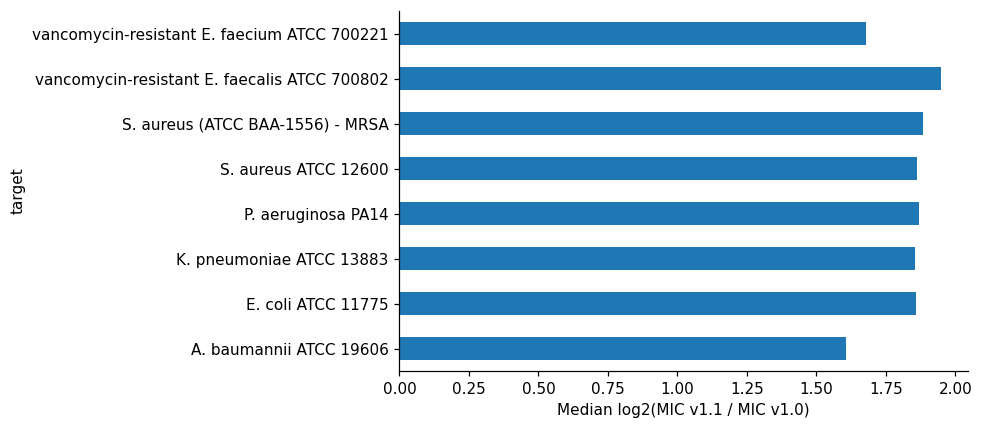

In [3]:
a0 = meta.loc[meta.model.eq('apex_1_0')]
a1 = meta.loc[meta.model.eq('apex_1_1')]
pairs = []
for right, row in a1.iterrows():
    left = a0.index[a0.strain_index.eq(row.strain_index)][0]
    pairs.append((left, right, bool(row.alias_unverified or meta.loc[left,'alias_unverified'])))
version_rows=[]
for left, right, flagged in pairs:
    x,y=np.log2(df[left]),np.log2(df[right]); delta=y-x
    k=int(np.ceil(len(df)*.01)); s0=set(x.nsmallest(k).index); s1=set(y.nsmallest(k).index)
    version_rows.append({'target':meta.loc[right,'target'], 'alias_unverified':flagged,
        'n':len(delta), 'median_log2_ratio':delta.median(), 'median_fold_ratio':2**delta.median(),
        'spearman':x.corr(y,method='spearman'), 'within_twofold':delta.abs().le(1).mean(),
        'discordant_at_32':df[left].le(32).ne(df[right].le(32)).mean(),
        'top_1pct_overlap_fraction':len(s0&s1)/k})
versions=pd.DataFrame(version_rows).set_index('target')
save_table(versions, 'apex_versions')
strict_pairs=[(l,r) for l,r,f in pairs if not f]
# Source-stratified follow-up distinguishes pooled collection effects from within-source drift.
source_drift=pd.DataFrame({meta.loc[r,'target']:np.log2(df[r]/df[l]) for l,r in strict_pairs}).groupby(features.source).median()
save_table(source_drift, 'apex_version_source_drift')
versions.loc[~versions.alias_unverified,'median_log2_ratio'].plot.barh(figsize=(9,4)); plt.xlabel('Median log2(MIC v1.1 / MIC v1.0)'); save_fig('apex_version_drift')

## 4. Approximate E. coli model agreement

Use the explicit ATCC 11775 APEX outputs and species-level MBC-Attention/AMPredictor. Their strain coverage differs, so these are approximate species-level comparisons. Compare log2 bias, rank agreement and shortlist overlap; repeat rank correlations within source collections. Correlation is not calibration or evidence of correctness.

**Rationale — describe alternatives a screener could actually choose.** The shared E. coli set allows a fair comparison of eligibility, but APEX specifies a strain while the other outputs use broader training targets. Mean or median log differences summarize numerical offsets; rank correlation describes ordering; overlap counts shared shortlist entries. A constant positive rescaling changes concentrations but leaves every rank unchanged, so these summaries answer different questions.

,left,right,n,spearman,median_log2_right_minus_left,median_abs_log2_difference,within_twofold,top_1pct_overlap_fraction
0,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,195625,0.799584,1.859119,1.859271,0.165996,0.385284
1,APEX_1.0_ATCC11775,MBC_Attention,194958,0.433720,-2.130429,2.170824,0.225746,0.009744
2,APEX_1.0_ATCC11775,AMPredictor,195614,0.363139,-2.739062,2.741057,0.149846,0.022483
3,APEX_1.1_ATCC11775,MBC_Attention,194958,0.507728,-3.896962,3.897216,0.047456,0.021538
4,APEX_1.1_ATCC11775,AMPredictor,195614,0.402102,-4.481781,4.481791,0.024487,0.017374
5,MBC_Attention,AMPredictor,194947,0.529613,-0.558946,1.256559,0.411168,0.054872


,source,left,right,n,spearman,median_log2_right_minus_left
0,AMPDIFF_synth50k,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,49986,0.790592,1.868604
1,AMPDIFF_synth50k,APEX_1.0_ATCC11775,MBC_Attention,49494,0.484907,-2.445095
2,AMPDIFF_synth50k,APEX_1.0_ATCC11775,AMPredictor,49983,0.445930,-3.158261
3,AMPDIFF_synth50k,APEX_1.1_ATCC11775,MBC_Attention,49494,0.442610,-4.254486
4,AMPDIFF_synth50k,APEX_1.1_ATCC11775,AMPredictor,49983,0.354248,-4.954489
5,AMPDIFF_synth50k,MBC_Attention,AMPredictor,49491,0.512791,-0.751163
6,Archaeomics,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,12623,0.550309,0.324817
7,Archaeomics,APEX_1.0_ATCC11775,MBC_Attention,12623,-0.104216,-2.607889
8,Archaeomics,APEX_1.0_ATCC11775,AMPredictor,12623,-0.066423,-2.984905
9,Archaeomics,APEX_1.1_ATCC11775,MBC_Attention,12623,-0.072432,-2.900388


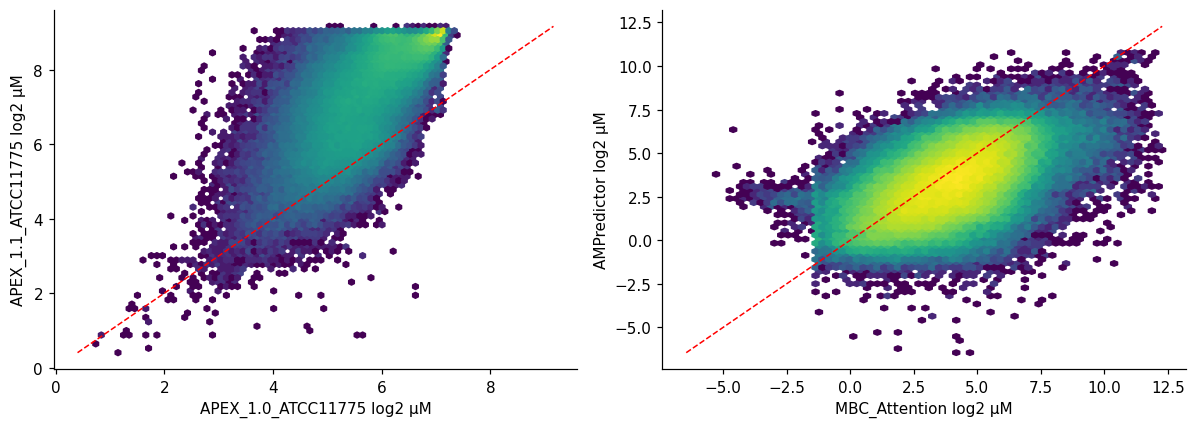

In [4]:
ecoli = pd.DataFrame({
 'APEX_1.0_ATCC11775':df['apex_1_0_E._coli_ATCC11775'],
 'APEX_1.1_ATCC11775':df['apex_1_1_E._coli_ATCC_11775'],
 'MBC_Attention':df['mbc_attention_E._coli_unspecified_strain'],
 'AMPredictor':df['ampredictor_E._coli_unspecified_strain']})
le=np.log2(ecoli)
rows=[]
for left,right in combinations(ecoli,2):
    z=le[[left,right]].dropna(); d=z[right]-z[left]; k=int(np.ceil(len(z)*.01))
    rows.append({'left':left,'right':right,'n':len(z),'spearman':z[left].corr(z[right],method='spearman'),
        'median_log2_right_minus_left':d.median(), 'median_abs_log2_difference':d.abs().median(),
        'within_twofold':d.abs().le(1).mean(),
        'top_1pct_overlap_fraction':len(set(z[left].nsmallest(k).index)&set(z[right].nsmallest(k).index))/k})
ecoli_agreement=pd.DataFrame(rows); save_table(ecoli_agreement,'ecoli_agreement')
within_source=[]
for src, idx in features.groupby('source').groups.items():
    for left,right in combinations(le,2):
        z=le.loc[idx,[left,right]].dropna()
        within_source.append({'source':src,'left':left,'right':right,'n':len(z), 'spearman':z[left].corr(z[right],method='spearman'), 'median_log2_right_minus_left':(z[right]-z[left]).median()})
save_table(pd.DataFrame(within_source),'ecoli_within_source')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,(left,right) in zip(axs,[('APEX_1.0_ATCC11775','APEX_1.1_ATCC11775'),('MBC_Attention','AMPredictor')]):
    z=le[[left,right]].dropna(); ax.hexbin(z[left],z[right],gridsize=65,bins='log',mincnt=1)
    lim=[z.min().min(),z.max().max()]; ax.plot(lim,lim,'r--',lw=1);ax.set(xlabel=left+' log2 µM',ylabel=right+' log2 µM')
save_fig('ecoli_agreement')

## 5. DeepAMP: fitted models, output labels and extreme values

Keep all four outputs separate. Quantify paired architecture/Gram-group differences and inspect concentration tails on the log scale. Examine prediction behaviour versus length and source before attributing extreme values to biology. Large extrapolated concentrations are model outputs, not measured resistance.

**Rationale — keep model variants and targets distinct.** CNN/LSTM comparisons within a DeepAMP head are closer target matches. The paper reports E. coli training for the negative head and B. subtilis for the positive head; their Gram labels do not establish activity across all species in either group. Cross-head rows in the code compare different intended targets. Quantiles show the output distribution, and large concentrations can reflect extrapolation or artificial inactive labels rather than measured resistance.

,0.01,0.25,0.50,0.75,0.95,0.99,1.00
deep_amp_cnn_neg,2.588000,11.197137,56.133307,9737.073975,10225.994141,10728.819336,36657.531250
deep_amp_cnn_pos,2.060182,11.566301,51.129881,7867.497192,10681.360352,11126.946533,29406.181641
deep_amp_lstm_neg,1.039961,16.763659,108.729321,9966.095947,10169.419922,10225.853271,65890.578125
deep_amp_lstm_pos,0.720116,8.199595,55.382410,9386.000488,10135.856201,10237.739502,467177.312500


,left,right,spearman,median_log2_right_minus_left,median_abs_log2_difference,within_twofold
0,deep_amp_cnn_neg,deep_amp_cnn_pos,0.789970,0.022453,0.906925,0.525037
1,deep_amp_cnn_neg,deep_amp_lstm_neg,0.765742,0.019518,1.066244,0.486321
2,deep_amp_cnn_neg,deep_amp_lstm_pos,0.747767,-0.041995,1.069194,0.484964
3,deep_amp_cnn_pos,deep_amp_lstm_neg,0.754977,0.069430,1.220183,0.454012
4,deep_amp_cnn_pos,deep_amp_lstm_pos,0.800736,-0.077027,0.982976,0.504333
5,deep_amp_lstm_neg,deep_amp_lstm_pos,0.744747,-0.085628,1.200214,0.464647


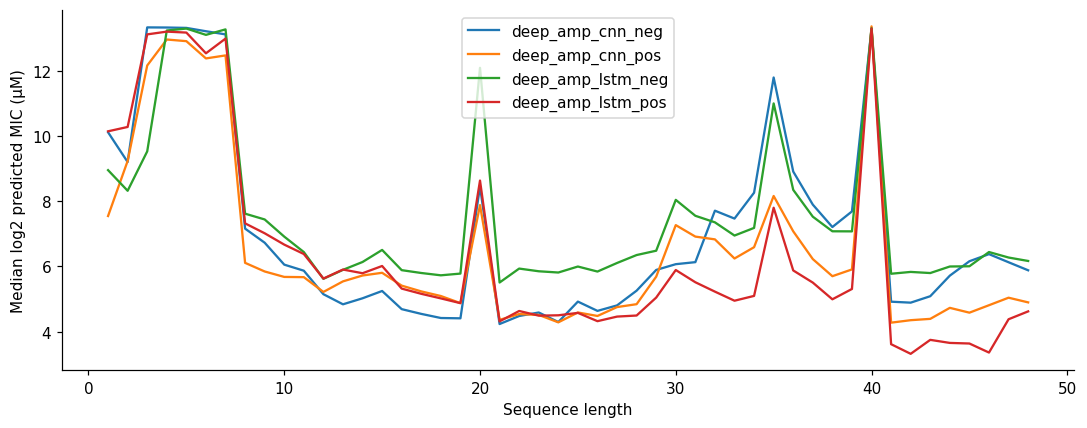

,deep_amp_cnn_neg,deep_amp_cnn_pos,deep_amp_lstm_neg,deep_amp_lstm_pos
source,,,,
AMPDIFF_synth50k,0.795703,0.790441,0.797463,0.794322
Archaeomics,0.123417,0.081594,0.161316,0.100054
DRAMP_APD_DBAASP,0.297863,0.272173,0.312923,0.287598
Extinctomics,0.13821,0.132621,0.188897,0.117052
Human_Proteomics,0.131236,0.08484,0.126942,0.061373
NEURIPS_AMP_CHALLENGE,0.45342,0.428541,0.478468,0.447695
Venomics,0.025033,0.018938,0.034393,0.017196
marlys_8to50_novel,0.676668,0.796686,0.79288,0.807882


deep_amp_cnn_neg        deep_amp_cnn_pos        deep_amp_lstm_neg  \
                 median  count           median  count            median   
length                                                                     
1           1104.107056      5       186.516556      5        494.091217   
2            588.020325     56       600.459259     56        318.805725   
3          10231.285156    132      4554.935791    132        735.918182   
4          10204.997559    474      7909.959717    474       9578.752930   
5          10124.519531    748      7637.949219    748       9981.869629   
6           9429.554199    888      5294.531738    888       8729.728516   
7           8820.650391   1331      5644.754883   1331       9808.840820   
8            142.712257   3318        69.023979   3318        196.078476   
9            105.853790   5940        57.469418   5940        173.411949   
10            66.450111   3831        51.197842   3831        120.453682   
11            58.418213   4621        50.946426   4621         86.795708   
12            35.471657   7631        37.224613   7631         49.171730   
13            28.619800   7402        46.577801   7402         59.493732   
14            32.527267   6655        52.765537   6655         70.290619   
15            37.978279   7056        55.891506   7056         90.810833   
16            25.831347   6279        42.548038   6279         59.098167   
17            23.354240   5919        37.645298   5919         55.641216   
18            21.399680   6002        34.129498   6002         52.974791   
19            21.258701   5200        29.356073   5200         54.950953   
20           348.656097  10082       235.159142  10082       4336.171387   
21            18.830984   6229        20.577669   6229         45.468891   
22            22.333086   4827        23.268908   4827         61.117752   
23            24.056064   4752        22.850173   4752         57.726416   
24            19.648718   4879        19.523230   4879         56.210335   
25            30.315128   4853        24.064020   4853         63.833611   
26            24.891541   4655        22.349760   4655         57.379578   
27            27.966163   4244        26.985900   4244         68.829918   
28            38.249866   3993        28.702351   3993         81.462959   
29            59.371536   4212        51.454468   4212         89.314388   
30            67.097160   4413       153.798416   4413        262.861420   
31            70.055206   4019       120.517311   4019        187.473724   
32           208.922699   3763       113.614311   3763        163.101028   
33           176.727341   3795        75.691299   3795        123.239990   
34           306.021118   3375        96.229576   3375        144.941391   
35          3531.292236   4068       285.380203   4068       2036.425232   
36           479.531860   3632       134.821190   3632        325.156616   
37           237.604141   3629        74.769287   3629        183.936523   
38           147.660980   3019        51.997353   3019        134.892242   
39           205.728592   2967        60.021515   2967        134.676178   
40          9984.541016  11223     10456.027344  11223      10057.510742   
41            30.259898   2016        19.386985   2016         54.761257   
42            29.645959   2016        20.430964   2016         56.929268   
43            33.991552   2038        21.013165   2038         55.587851   
44            52.605850   2101        26.549046   2101         63.871891   
45            71.413616   2098        23.969435   2098         64.188931   
46            83.065872   2215        28.076473   2215         86.846664   
47            69.893097   2155        32.928226   2155         77.273445   
48            58.939943   2120        29.816928   2120         71.834648   
49                  NaN      0              NaN      0               NaN   
50                  NaN      0              NaN      0 

In [5]:
deep_cols=meta.index[meta.model.str.startswith('deep_amp')]
deep=df[deep_cols].copy();deep.columns=meta.loc[deep_cols,'model'].to_numpy()
ld=np.log2(deep)
save_table(deep.quantile([.01,.25,.5,.75,.95,.99,1]).T,'deepamp_quantiles')
rows=[]
for left,right in combinations(deep,2):
    z=ld[[left,right]].dropna();d=z[right]-z[left]
    rows.append({'left':left,'right':right,'spearman':z[left].corr(z[right],method='spearman'), 'median_log2_right_minus_left':d.median(),'median_abs_log2_difference':d.abs().median(),'within_twofold':d.abs().le(1).mean()})
save_table(pd.DataFrame(rows),'deepamp_agreement')
length_deep=ld.groupby(features.length).median()
length_deep.plot(figsize=(10,4));plt.ylabel('Median log2 predicted MIC (µM)');plt.xlabel('Sequence length');save_fig('deepamp_length')
# Separate high-output mass from general tails; cutoff is diagnostic only.
save_table(deep.gt(1000).where(deep.notna()).groupby(features.source).mean(),'deepamp_above_1000_by_source')
save_table(deep.assign(length=features.length).groupby('length').agg(['median','count']), 'deepamp_by_length')

## 6. Classification disagreement and output-type audit

Analyze the three probability outputs and binary AMP-CLIP consensus separately from MIC regression. A 0.5 score cutoff is an exploratory rule, not an independently verified 50% probability or calibration across models. Repeat at 0.3 and 0.7. Missing predictions are excluded from complete-case voting, never counted as negatives. AMP-Read is analyzed only as a native log score.

**Rationale — examine the activity-screening stage separately.** A general AMP label is not a strain-specific MIC. A positive vote means score ≥ the stated cutoff; mixed voting means at least one positive and one negative. AMP-CLIP is already binary, so changing 0.3/0.5/0.7 varies only the other scores. A 0.5 rule does not establish a common 50% probability, sensitivity, or specificity across tools.

,threshold,n,all_positive,all_negative,mixed
0,0.3,195620,0.293748,0.068546,0.637706
1,0.5,195620,0.217999,0.127175,0.654826
2,0.7,195620,0.105393,0.190701,0.703906


,positive_fraction
macrel_general_AMP,0.468291
ai4amp_general_AMP,0.609472
amp_clip_general_AMP,0.476592
amplify_general_AMP,0.618377


,macrel_general_AMP,ai4amp_general_AMP,amp_clip_general_AMP,amplify_general_AMP
macrel_general_AMP,1.000000,0.404244,0.399807,0.187864
ai4amp_general_AMP,0.404244,1.000000,0.280247,0.217376
amp_clip_general_AMP,0.399807,0.280247,1.000000,0.153343
amplify_general_AMP,0.187864,0.217376,0.153343,1.000000


,macrel_general_AMP,ai4amp_general_AMP,amp_clip_general_AMP,amplify_general_AMP
source,,,,
AMPDIFF_synth50k,0.520537,0.665346,0.485185,0.160335
Archaeomics,0.366395,0.614909,0.307692,0.903193
DRAMP_APD_DBAASP,0.563099,0.685372,0.709174,0.750815
Extinctomics,0.312782,0.465811,0.395336,0.731789
Human_Proteomics,0.563368,0.678056,0.345436,0.903919
NEURIPS_AMP_CHALLENGE,0.393145,0.481819,0.636121,0.575794
Venomics,0.637072,0.948896,0.739498,0.973798
marlys_8to50_novel,0.366939,0.508813,0.640800,0.529450


,spearman_with_native_AMPRead
APEX_1.0_ATCC11775,0.253060
APEX_1.1_ATCC11775,0.262805
MBC_Attention,0.153267
AMPredictor,0.118460
deep_amp_cnn_neg,0.266237
deep_amp_cnn_pos,0.232781
deep_amp_lstm_neg,0.239945
deep_amp_lstm_pos,0.142983
length,0.169669
charge_density,-0.360615


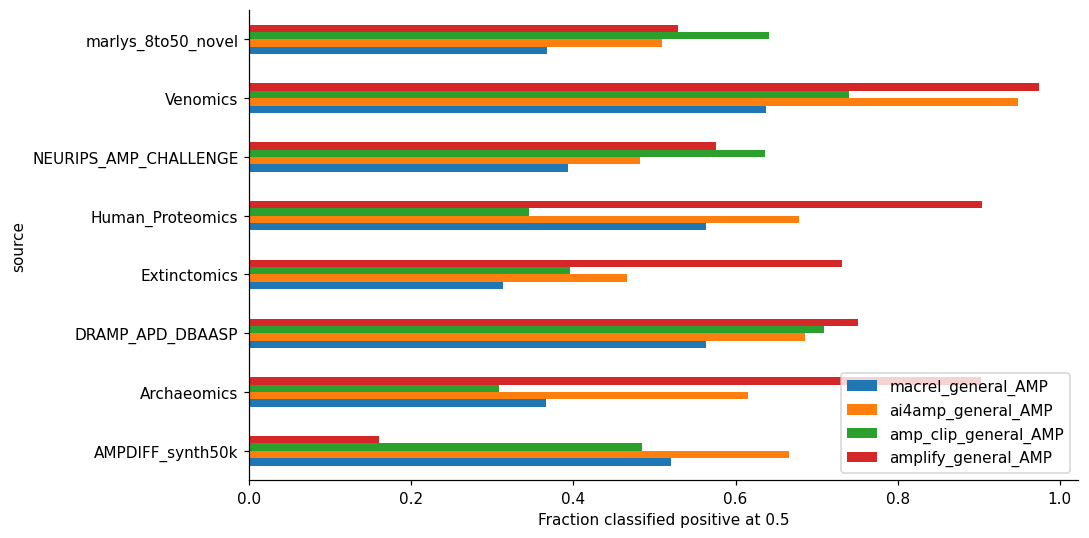

In [6]:
class_cols=meta.index[meta.output_kind.isin(['AMP_probability','AMP_binary_consensus'])]
cp=df[class_cols]; complete=cp.dropna()
class_rows=[]
for threshold in [.3,.5,.7]:
    votes=complete.ge(threshold); nv=votes.sum(axis=1)
    class_rows.append({'threshold':threshold,'n':len(complete),'all_positive':nv.eq(4).mean(), 'all_negative':nv.eq(0).mean(),'mixed':nv.between(1,3).mean()})
classifier_summary=pd.DataFrame(class_rows);save_table(classifier_summary,'classifier_consensus')
votes=complete.ge(.5)
save_table(pd.DataFrame({'positive_fraction':votes.mean()}),'classifier_positive_rates')
save_table(votes.astype(int).corr(),'classifier_phi')
source_class=votes.assign(source=features.source).groupby('source').mean()
save_table(source_class,'classifier_by_source')
read=df['amp_read_unspecified_target']
read_assoc=pd.concat([le,ld,features.drop(columns='source'), cp],axis=1).corrwith(read,method='spearman').rename('spearman_with_native_AMPRead')
save_table(read_assoc.to_frame(),'ampread_associations')
ax=source_class.plot.barh(figsize=(10,5));ax.set_xlabel('Fraction classified positive at 0.5');save_fig('classifiers_by_source')

## 7. Follow-up: sequence features and stratified associations

Quantify associations with length, an approximate charge-density proxy (K+R−D−E divided by length), hydrophobic residue fraction, cysteine fraction and composition entropy. These are descriptive sequence proxies, not measured charge, folding or membrane activity. Within-source correlations and within-length-bin checks test whether pooled associations persist after partial stratification; neither establishes causality.

**Rationale — test whether sequence summaries accompany model behavior.** Length, residue content, and predicted activity can all differ by source. Within-source and length-restricted checks ask whether a pooled association remains under more comparable sampling. Spearman coefficients range from −1 to +1 and describe monotonic ordering. Composition entropy measures residue diversity in bits, not structure; none of these associations identifies a causal residue effect.

In [7]:
pred_log=pd.concat([le,ld],axis=1)
feature_cols=features.columns.drop('source').tolist()
assoc=pd.DataFrame({c:features[feature_cols].corrwith(pred_log[c],method='spearman') for c in pred_log})
save_table(assoc,'sequence_associations')
strat=[]
for src,idx in features.groupby('source').groups.items():
    for col in pred_log:
        strat.append({'source':src,'prediction':col,'n':int(pred_log.loc[idx,col].notna().sum()),
                      **{f:features.loc[idx,f].corr(pred_log.loc[idx,col],method='spearman') for f in feature_cols}})
save_table(pd.DataFrame(strat),'sequence_associations_by_source')
# The sign and magnitude of length associations are specifically checked within each source.
length_bin=pd.cut(features.length,[0,10,20,30,40,50])
charge_strata=[]
for (src,bin_),idx in features.groupby([features.source,length_bin],observed=True).groups.items():
    if len(idx)<100: continue
    for col in ['APEX_1.1_ATCC11775','MBC_Attention','AMPredictor']:
        z=pd.concat([features.loc[idx,'charge_density'],pred_log.loc[idx,col]],axis=1).dropna()
        charge_strata.append({'source':src,'length_bin':str(bin_),'prediction':col,'n':len(z),'rho_charge':z.iloc[:,0].corr(z.iloc[:,1],method='spearman')})
save_table(pd.DataFrame(charge_strata),'charge_within_source_length')

,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,MBC_Attention,AMPredictor,deep_amp_cnn_neg,deep_amp_cnn_pos,deep_amp_lstm_neg,deep_amp_lstm_pos
length,-0.108065,-0.200068,-0.481253,-0.520851,0.016918,-0.001028,0.081948,-0.014449
charge_density,-0.595569,-0.615562,-0.384337,-0.246975,-0.423480,-0.465820,-0.429610,-0.454577
hydrophobic_fraction,-0.217653,-0.074360,0.111330,0.078915,-0.239696,-0.177890,-0.266399,-0.201470
cys_fraction,0.333476,0.265555,-0.028895,-0.094730,0.149671,0.165933,0.164443,0.183606
entropy_bits,0.136310,0.049107,-0.265001,-0.298724,0.182688,0.167798,0.227562,0.162413


,source,prediction,n,length,charge_density,hydrophobic_fraction,cys_fraction,entropy_bits
0,AMPDIFF_synth50k,APEX_1.0_ATCC11775,49986,-0.017461,-0.598345,-0.175611,0.226740,0.225540
1,AMPDIFF_synth50k,APEX_1.1_ATCC11775,49986,0.089009,-0.606115,-0.097208,0.241259,0.311994
2,AMPDIFF_synth50k,MBC_Attention,49494,-0.319069,-0.326141,0.072293,-0.064742,-0.142924
3,AMPDIFF_synth50k,AMPredictor,49983,-0.390622,-0.237723,0.079417,-0.190860,-0.194600
4,AMPDIFF_synth50k,deep_amp_cnn_neg,49986,0.071800,-0.165799,-0.092221,0.093333,0.217915
...,...,...,...,...,...,...,...,...
59,marlys_8to50_novel,AMPredictor,4652,-0.502440,-0.461200,-0.037204,0.251455,-0.325590
60,marlys_8to50_novel,deep_amp_cnn_neg,4466,-0.271299,-0.430824,-0.112590,0.006655,-0.124336
61,marlys_8to50_novel,deep_amp_cnn_pos,4466,-0.055484,-0.504812,-0.084772,-0.007689,0.064444
62,marlys_8to50_novel,deep_amp_lstm_neg,4466,0.026837,-0.402842,-0.145015,-0.014384,0.119376


,source,length_bin,prediction,n,rho_charge
0,AMPDIFF_synth50k,"(0, 10]",APEX_1.1_ATCC11775,5299,-0.292685
1,AMPDIFF_synth50k,"(0, 10]",MBC_Attention,4807,-0.257150
2,AMPDIFF_synth50k,"(0, 10]",AMPredictor,5299,-0.054792
3,AMPDIFF_synth50k,"(10, 20]",APEX_1.1_ATCC11775,12334,-0.594439
4,AMPDIFF_synth50k,"(10, 20]",MBC_Attention,12334,-0.424326
...,...,...,...,...,...
106,marlys_8to50_novel,"(30, 40]",MBC_Attention,1177,-0.356008
107,marlys_8to50_novel,"(30, 40]",AMPredictor,1177,-0.604635
108,marlys_8to50_novel,"(40, 50]",APEX_1.1_ATCC11775,726,-0.733549
109,marlys_8to50_novel,"(40, 50]",MBC_Attention,726,-0.453534


## 8. APEX target spectrum versus a common peptide potency axis

Within each version, decompose log2 predictions into a grand mean, peptide effect, target effect and residual interaction. This balanced descriptive decomposition separates broad peptide ranking from target offsets and peptide-specific spectrum. PCA quantifies shared variation without interpreting components as mechanisms. A high variance fraction on one axis suggests redundancy among predicted target profiles, not biological equivalence of organisms.

**Rationale — distinguish a shared prediction pattern from target-specific variation.** The decomposition separates peptide averages, target averages, and their remaining interaction on the log scale. Its variance fractions divide squared deviations by total squared deviations. PCA's first-component fraction describes how much numerical variation one fitted axis captures, not explained biological activity or predictive R². Different target panels can change these fractions without a change in model quality.

,median_MIC_uM,median_log2_MIC,fraction_le_32
apex_1_0_E._coli_ATCC11775,70.161575,6.132609,0.115461
apex_1_0_P._aeruginosa_PAO1,88.122528,6.461439,0.116590
apex_1_0_P._aeruginosa_PA14,86.393234,6.432846,0.107773
apex_1_0_S._aureus_ATCC12600,97.493744,6.607238,0.014175
apex_1_0_E._coli_AIG221,65.686073,6.037516,0.199637
apex_1_0_E._coli_AIG222,60.625740,5.921859,0.215371
apex_1_0_K._pneumoniae_ATCC13883,95.350792,6.575173,0.004212
apex_1_0_A._baumannii_ATCC19606,47.418251,5.567371,0.354929
apex_1_0_A._muciniphila_ATCC_BAA-835,50.716911,5.664395,0.345467
apex_1_0_B._fragilis_ATCC25285,109.433777,6.773914,0.006783


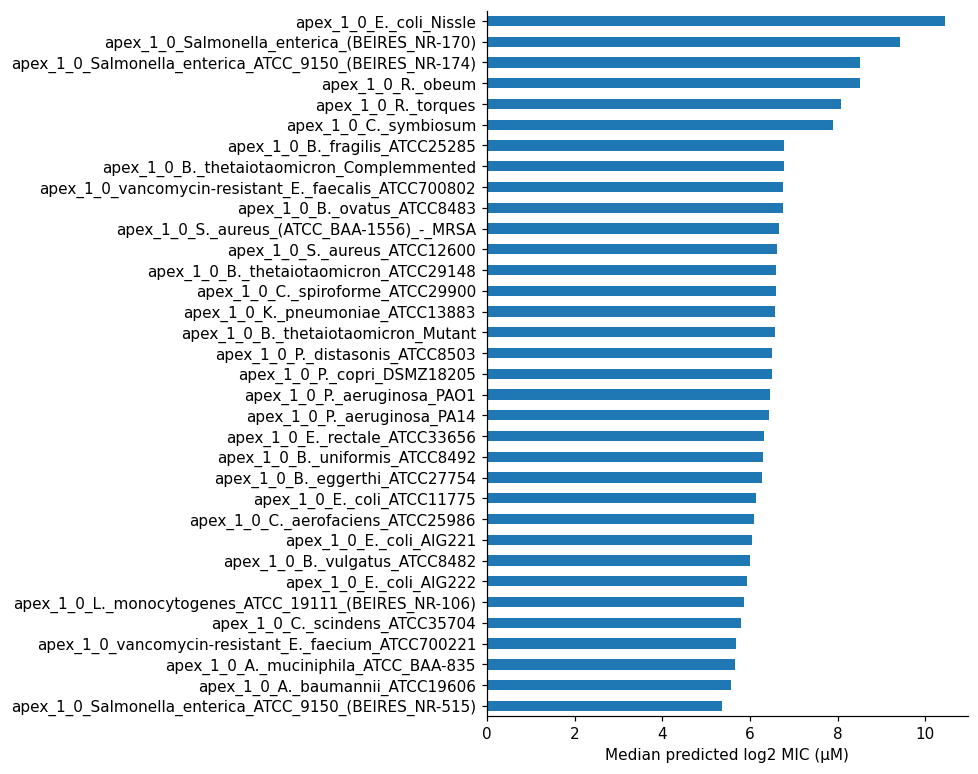

,median_MIC_uM,median_log2_MIC,fraction_le_32
apex_1_1_A._baumannii_ATCC_19606,151.901306,7.246990,0.212233
apex_1_1_E._coli_ATCC_11775,295.062836,8.204878,0.029751
apex_1_1_E._coli_AIC221,204.353745,7.674925,0.122909
apex_1_1_E._coli_AIC222,224.116791,7.808107,0.091481
apex_1_1_K._pneumoniae_ATCC_13883,374.669128,8.549473,0.002152
apex_1_1_P._aeruginosa_PA01,322.369507,8.332571,0.020723
apex_1_1_P._aeruginosa_PA14,328.032654,8.357696,0.010863
apex_1_1_S._aureus_ATCC_12600,384.429077,8.586574,0.002965
apex_1_1_S._aureus_(ATCC_BAA-1556)_-_MRSA,426.110352,8.735083,0.002101
apex_1_1_vancomycin-resistant_E._faecalis_ATCC_700802,454.816010,8.829139,0.000097


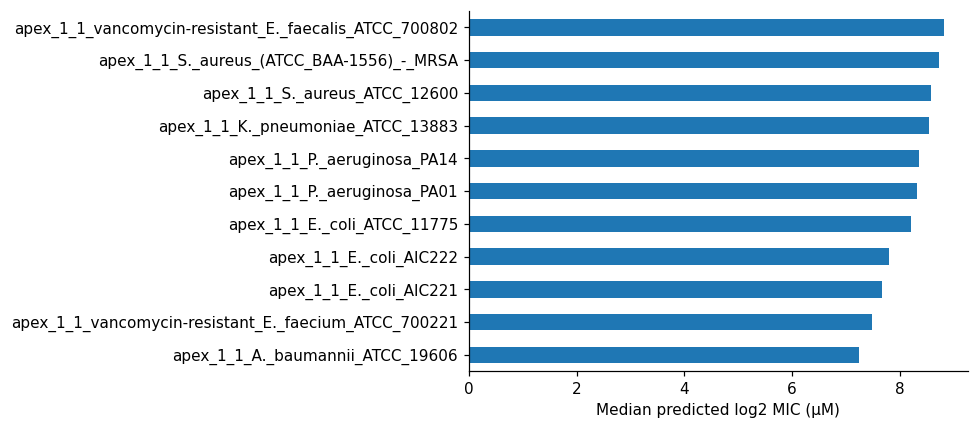

,model,n_targets,peptide_effect_fraction,target_effect_fraction,interaction_fraction,PC1_fraction_column_centered,PC1_3_fraction
0,apex_1_0,34,0.217143,0.647211,0.135646,0.755701,0.895692
1,apex_1_1,11,0.596196,0.187345,0.216459,0.891473,0.945943


In [8]:
spectrum_rows=[]
for model in ['apex_1_0','apex_1_1']:
    cols=meta.index[meta.model.eq(model)]; z=np.log2(df[cols]); a=z.to_numpy();grand=a.mean()
    row=a.mean(axis=1,keepdims=True); col=a.mean(axis=0,keepdims=True)
    resid=a-row-col+grand; total=((a-grand)**2).sum()
    pca=PCA(n_components=3).fit(a)
    spectrum_rows.append({'model':model,'n_targets':len(cols), 'peptide_effect_fraction':len(cols)*((row-grand)**2).sum()/total,
        'target_effect_fraction':len(df)*((col-grand)**2).sum()/total,'interaction_fraction':(resid**2).sum()/total,
        'PC1_fraction_column_centered':pca.explained_variance_ratio_[0], 'PC1_3_fraction':pca.explained_variance_ratio_.sum()})
    target_summary=pd.DataFrame({'median_MIC_uM':df[cols].median(),'median_log2_MIC':z.median(),'fraction_le_32':df[cols].le(32).mean()})
    save_table(target_summary,model+'_target_summary')
    target_summary.median_log2_MIC.sort_values().plot.barh(figsize=(9,max(4,len(cols)*.21)));plt.xlabel('Median predicted log2 MIC (µM)');save_fig(model+'_target_offsets')
save_table(pd.DataFrame(spectrum_rows),'apex_spectrum_decomposition')

## 9. Follow-up: shortlist stability and interpretation limits

At several exploratory MIC cutoffs, quantify E. coli model consensus. This tests robustness to arbitrary screening thresholds. Export a small diagnostic set of strongly disagreeing sequences; it is not an efficacy shortlist. Sequence similarity and overlapping training data mean rows and models are not independent. The TSV has no ground-truth MIC column, so accuracy and biological selectivity cannot be established.

**Rationale — translate disagreement into a screening rule.** Cutoff counts indicate how many predictions meet a chosen concentration rule. All-pass, all-fail, and mixed cases partition the shared eligible set; the denominator must accompany each percentage. These four-output historical calculations include both APEX versions and must not be silently substituted for the later three-tool analysis. A low predicted MIC or consensus does not establish a laboratory hit.

In [9]:
threshold_rows=[]
for t in [8,16,32,64]:
    ok=ecoli.dropna();v=ok.le(t)
    threshold_rows.append({'MIC_cutoff_uM':t,'n_complete':len(ok), 'all_four_below':v.all(axis=1).sum(),'all_four_above':(~v).all(axis=1).sum(),'mixed':(v.any(axis=1)&~v.all(axis=1)).sum(),**v.mean().to_dict()})
save_table(pd.DataFrame(threshold_rows),'ecoli_threshold_sensitivity')
disagreement=le.max(axis=1)-le.min(axis=1)
# Require complete cases so coverage does not determine which rows enter the tail.
idx=disagreement.loc[le.notna().all(axis=1)].nlargest(30).index
save_table(features.loc[idx].join(ecoli.loc[idx]).assign(log2_range=disagreement.loc[idx]),'ecoli_disagreement_diagnostics')
print('Ground-truth MIC columns: none. No accuracy, calibrated uncertainty or clinical susceptibility inferred.')

,MIC_cutoff_uM,n_complete,all_four_below,all_four_above,mixed,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,MBC_Attention,AMPredictor
0,8,194947,51,88876,106020,0.001180,0.001354,0.329654,0.451010
1,16,194947,484,50343,144120,0.013824,0.006987,0.516428,0.647314
2,32,194947,3852,21853,169242,0.115862,0.029854,0.711840,0.810692
3,64,194947,20624,5876,168447,0.446434,0.112518,0.869426,0.926421


,length,charge_density,hydrophobic_fraction,cys_fraction,entropy_bits,source,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,MBC_Attention,AMPredictor,log2_range
sequence,,,,,,,,,,,
VGIGTPISFYGGGAGHVPEYF,21,-0.047619,0.428571,0.000000,3.177566,NEURIPS_AMP_CHALLENGE,138.303268,508.790405,24.010313,0.011432,15.441655
GGAGHVPEYFVGIGTPISFYG,21,-0.047619,0.428571,0.000000,3.177566,DRAMP_APD_DBAASP,135.982819,505.767212,18.410715,0.011727,15.396372
GGAGHVPEYFVYIGTPISFYG,21,-0.047619,0.476190,0.000000,3.232102,NEURIPS_AMP_CHALLENGE,136.185104,508.083649,19.763695,0.019091,14.699906
VGIGTPIFSYGGGAGHVPEYF,21,-0.047619,0.428571,0.000000,3.177566,NEURIPS_AMP_CHALLENGE,138.251617,508.555115,17.998632,0.023938,14.374832
TTKNYGNGVCNSVNWCQCGNVWASCNLATGCAAWLCKLA,39,0.051282,0.384615,0.153846,3.396973,DRAMP_APD_DBAASP,127.263390,469.508301,0.025766,13.262757,14.153406
TPALAVVTTVLPAAAVTTAKSV,22,0.045455,0.590909,0.000000,2.517202,DRAMP_APD_DBAASP,134.161285,496.334045,0.042673,78.572266,13.505688
GHSVDRIPEYFGPPGLPGPVLFYG,24,-0.041667,0.375000,0.000000,3.284159,NEURIPS_AMP_CHALLENGE,133.339233,474.920837,81.547501,0.051485,13.171242
MKRNHGRKYRKKKRKNGGRHKKRKYNPNKNRKGKRKGKKK,40,0.600000,0.075000,0.000000,2.441446,AMPDIFF_synth50k,72.721451,378.515533,7.190902,0.043501,13.087011
KYYGNGVCNSVNWCQCGNVWASCNLATGCAAWLCKLA,37,0.054054,0.432432,0.162162,3.398812,DRAMP_APD_DBAASP,118.276711,467.626312,0.068383,14.809006,12.739440


Ground-truth MIC columns: none. No accuracy, calibrated uncertainty or clinical susceptibility inferred.


## 10. Follow-up: does target coverage explain the APEX spectrum difference?

The initial decomposition used 34 targets for v1.0 and 11 for v1.1. Repeat it on exactly the eight unambiguously matched targets, then inspect correlations after removing each peptide’s mean and each target’s mean. This controls panel composition and asks whether peptide-specific target preferences reproduce across versions. Residual correlations describe prediction reproducibility; they do not validate biological specificity.

**Rationale — check whether panel composition created the apparent version difference.** Using the same eight unambiguous targets prevents the 34-versus-11 output count from driving the comparison. Removing row and column means isolates what remains after shared peptide and target offsets. Correlation of those residuals describes reproducibility of model patterns, not independent evidence of organism selectivity. PC1 still measures numerical variance, not accuracy.

In [10]:

matched_spectrum=[]
residuals={}
for name,cols in [('v1.0',[l for l,r in strict_pairs]),('v1.1',[r for l,r in strict_pairs])]:
    a=np.log2(df[cols]).to_numpy(); grand=a.mean()
    row=a.mean(axis=1,keepdims=True); col=a.mean(axis=0,keepdims=True)
    res=a-row-col+grand; total=((a-grand)**2).sum(); residuals[name]=res
    matched_spectrum.append({'version':name,'n_targets':len(cols),
        'peptide_fraction':len(cols)*((row-grand)**2).sum()/total,
        'target_fraction':len(a)*((col-grand)**2).sum()/total,
        'interaction_fraction':(res**2).sum()/total,
        'PC1_fraction':PCA(n_components=1).fit(a).explained_variance_ratio_[0]})
save_table(pd.DataFrame(matched_spectrum),'matched_spectrum')
save_table(pd.DataFrame([{'target':meta.loc[r,'target'],
    'residual_spearman':pd.Series(residuals['v1.0'][:,i]).corr(pd.Series(residuals['v1.1'][:,i]),method='spearman')}
    for i,(l,r) in enumerate(strict_pairs)]),'spectrum_residual_reproducibility')


,version,n_targets,peptide_fraction,target_fraction,interaction_fraction,PC1_fraction
0,v1.0,8,0.542915,0.240426,0.216659,0.881191
1,v1.1,8,0.520748,0.232348,0.246904,0.876850


,target,residual_spearman
0,A. baumannii ATCC 19606,0.833284
1,E. coli ATCC 11775,0.442718
2,K. pneumoniae ATCC 13883,0.799715
3,P. aeruginosa PA14,0.534314
4,S. aureus ATCC 12600,0.795728
5,S. aureus (ATCC BAA-1556) - MRSA,0.841054
6,vancomycin-resistant E. faecalis ATCC 700802,0.856394
7,vancomycin-resistant E. faecium ATCC 700221,0.782208


## 11. Follow-up: shortlist size and source composition

The initial top-1% overlaps were small. Repeat on a common complete-case universe at 0.5%, 1%, 5%, and 10%; use sequence order to break ties reproducibly. The expected overlap fraction k/N is a descriptive independent-random-list reference, not a significance test. Source composition and within-source overlap reveal whether collection membership drives prioritization. Source labels reflect upstream deduplication precedence, not exclusive biological origin.

**Rationale — test dependence on experimental budget and source sampling.** A top-1% result may not describe a top-10% decision, so selection is repeated at several list sizes. Shared fraction means intersection count divided by the common list size k, not the union. The k/N random-list reference assumes independent uniform selection and is not a significance result. Source-restricted comparisons address one sampling explanation without making source groups independent experiments.

In [11]:

ok=ecoli.dropna().sort_index(); shortlist_rows=[]; shortlist_sources=[]
for fraction in [.005,.01,.05,.1]:
    k=int(np.ceil(len(ok)*fraction))
    selected={c:set(ok[c].nsmallest(k).index) for c in ok}
    for l,r in combinations(ok,2):
        overlap=len(selected[l]&selected[r])
        shortlist_rows.append({'fraction':fraction,'left':l,'right':r,'n':len(ok),'k':k,
            'overlap_count':overlap,'overlap_fraction':overlap/k,'random_reference':k/len(ok)})
    if fraction==.01:
        for c,idx in selected.items():
            for src,count in features.loc[sorted(idx),'source'].value_counts().items():
                shortlist_sources.append({'model':c,'source':src,'count':count,'fraction':count/k})
save_table(pd.DataFrame(shortlist_rows),'shortlist_sensitivity')
save_table(pd.DataFrame(shortlist_sources),'shortlist_sources')
within=[]
for src,idx in features.groupby('source').groups.items():
    z=ok.loc[ok.index.intersection(idx)];k=int(np.ceil(len(z)*.01))
    for l,r in combinations(z,2):
        within.append({'source':src,'left':l,'right':r,'n':len(z),'k':k,
                      'overlap_fraction':len(set(z[l].nsmallest(k).index)&set(z[r].nsmallest(k).index))/k})
save_table(pd.DataFrame(within),'shortlist_within_source')


,fraction,left,right,n,k,overlap_count,overlap_fraction,random_reference
0,0.005,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,194947,975,364,0.373333,0.005001
1,0.005,APEX_1.0_ATCC11775,MBC_Attention,194947,975,5,0.005128,0.005001
2,0.005,APEX_1.0_ATCC11775,AMPredictor,194947,975,16,0.016410,0.005001
3,0.005,APEX_1.1_ATCC11775,MBC_Attention,194947,975,9,0.009231,0.005001
4,0.005,APEX_1.1_ATCC11775,AMPredictor,194947,975,11,0.011282,0.005001
5,0.005,MBC_Attention,AMPredictor,194947,975,38,0.038974,0.005001
6,0.010,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,194947,1950,752,0.385641,0.010003
7,0.010,APEX_1.0_ATCC11775,MBC_Attention,194947,1950,19,0.009744,0.010003
8,0.010,APEX_1.0_ATCC11775,AMPredictor,194947,1950,43,0.022051,0.010003
9,0.010,APEX_1.1_ATCC11775,MBC_Attention,194947,1950,42,0.021538,0.010003


,model,source,count,fraction
0,APEX_1.0_ATCC11775,NEURIPS_AMP_CHALLENGE,462,0.236923
1,APEX_1.0_ATCC11775,Human_Proteomics,373,0.191282
2,APEX_1.0_ATCC11775,DRAMP_APD_DBAASP,363,0.186154
3,APEX_1.0_ATCC11775,AMPDIFF_synth50k,313,0.160513
4,APEX_1.0_ATCC11775,Archaeomics,246,0.126154
5,APEX_1.0_ATCC11775,Venomics,100,0.051282
6,APEX_1.0_ATCC11775,Extinctomics,92,0.047179
7,APEX_1.0_ATCC11775,marlys_8to50_novel,1,0.000513
8,APEX_1.1_ATCC11775,Archaeomics,453,0.232308
9,APEX_1.1_ATCC11775,AMPDIFF_synth50k,400,0.205128


,source,left,right,n,k,overlap_fraction
0,AMPDIFF_synth50k,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,49491,495,0.571717
1,AMPDIFF_synth50k,APEX_1.0_ATCC11775,MBC_Attention,49491,495,0.034343
2,AMPDIFF_synth50k,APEX_1.0_ATCC11775,AMPredictor,49491,495,0.052525
3,AMPDIFF_synth50k,APEX_1.1_ATCC11775,MBC_Attention,49491,495,0.036364
4,AMPDIFF_synth50k,APEX_1.1_ATCC11775,AMPredictor,49491,495,0.050505
5,AMPDIFF_synth50k,MBC_Attention,AMPredictor,49491,495,0.052525
6,Archaeomics,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,12623,127,0.307087
7,Archaeomics,APEX_1.0_ATCC11775,MBC_Attention,12623,127,0.000000
8,Archaeomics,APEX_1.0_ATCC11775,AMPredictor,12623,127,0.000000
9,Archaeomics,APEX_1.1_ATCC11775,MBC_Attention,12623,127,0.000000


## 12. Follow-up: source effects after length stratification

DeepAMP assigns extreme concentrations disproportionately to certain collections, while AMPlify shows a different source pattern. Compare DeepAMP high-output fractions and AMPlify positives within length bands. These checks address one compositional explanation, but cannot establish generalization failure without experimental labels. Inspect E. coli ranking after residualizing within-source ranks against length and composition proxies; this is a sensitivity analysis, not causal adjustment.

**Rationale — ask whether source differences are mostly length differences.** Comparing collections within length bands reduces one source of composition imbalance. The >1,000 µM statistic is the fraction of available predictions above that numerical rule, not measured inactivity. Correlations after subtracting fitted feature relationships describe remaining association. They do not isolate a causal training-domain effect, and high DeepAMP outputs may reflect its non-AMP label convention.

In [12]:

stratum=features[['source']].assign(length_bin=pd.cut(features.length,[0,10,20,30,40,50]))
stratum['deep_lstm_pos_gt1000']=deep['deep_amp_lstm_pos'].gt(1000).where(deep['deep_amp_lstm_pos'].notna())
stratum['amplify_positive']=cp['amplify_general_AMP'].ge(.5).where(cp['amplify_general_AMP'].notna())
save_table(stratum.groupby(['source','length_bin'],observed=True).agg(
    n=('amplify_positive','count'),deep_n=('deep_lstm_pos_gt1000','count'),
    deep_high_fraction=('deep_lstm_pos_gt1000','mean'),amplify_positive=('amplify_positive','mean')),'source_length_sensitivity')
adjusted=[]
for src,idx in features.groupby('source').groups.items():
    z=le.loc[idx].dropna(); X=features.loc[z.index,feature_cols].rank(pct=True).to_numpy()
    X=np.column_stack([np.ones(len(z)),X]);Y=z.rank(pct=True).to_numpy()
    residual=Y-X@np.linalg.lstsq(X,Y,rcond=None)[0]
    corr=np.corrcoef(residual,rowvar=False)
    for i,j in combinations(range(len(z.columns)),2):
        adjusted.append({'source':src,'left':z.columns[i],'right':z.columns[j],
                         'n':len(z),'rank_residual_correlation':corr[i,j]})
save_table(pd.DataFrame(adjusted),'composition_adjusted_agreement')


n  deep_n deep_high_fraction  \
source                length_bin                                     
AMPDIFF_synth50k      (0, 10]      5299    5299           0.645971   
                      (10, 20]    12334   12334           0.682504   
                      (20, 30]    13259   13259           0.766046   
                      (30, 40]    19093   19093           0.927408   
                      (40, 50]        1       1                0.0   
Archaeomics           (0, 10]        16      16                0.0   
                      (10, 20]     2802    2802           0.015346   
                      (20, 30]     2217    2217           0.023004   
                      (30, 40]     2397    2397           0.079266   
                      (40, 50]     5191    3782           0.221576   
DRAMP_APD_DBAASP      (0, 10]      3918    3918           0.303726   
                      (10, 20]     7298    7298           0.190052   
                      (20, 30]     4178    4178           0.226424   
                      (30, 40]     2590    2590           0.492664   
                      (40, 50]     1638    1206           0.597015   
Extinctomics          (0, 10]       728     728           0.082418   
                      (10, 20]    17500   17500           0.101429   
                      (20, 30]    10179   10179           0.116121   
                      (30, 40]     5809    5809           0.150456   
                      (40, 50]     2960    2460           0.163415   
Human_Proteomics      (0, 10]      2999    2999           0.022007   
                      (10, 20]     9997    9997           0.027608   
                      (20, 30]     9999    9999           0.042904   
                      (30, 40]    10000   10000             0.0706   
                      (40, 50]    10000    8000           0.129875   
NEURIPS_AMP_CHALLENGE (0, 10]      3516    3516           0.540387   
                      (10, 20]    14861   14861           0.426755   
                      (20, 30]     3521    3521           0.348481   
                      (30, 40]     1273    1273           0.586803   
                      (40, 50]      782     584           0.717466   
Venomics              (0, 10]         3       3                0.0   
                      (10, 20]     1078    1078           0.010204   
                      (20, 30]     2176    2176            0.01057   
                      (30, 40]     1151    1151           0.024327   
                      (40, 50]      210     186           0.091398   
marlys_8to50_novel    (0, 10]       244     244           0.881148   
                      (10, 20]      977     977           0.724667   
                      (20, 30]     1528    1528           0.873691   
                      (30, 40]     1177    1177           0.796941   
                      (40, 50]      726     540           0.762963   

                                  amplify_positive  
source                length_bin                    
AMPDIFF_synth50k      (0, 10]             0.285148  
                      (10, 20]            0.194746  
                      (20, 30]            0.175051  
                      (30, 40]            0.093228  
                      (40, 50]            1.000000  
Archaeomics           (0, 10]             1.000000  
                      (10, 20]            0.938972  
                      (20, 30]            0.912043  
                      (30, 40]            0.869420  
                      (40, 50]            0.895396  
DRAMP_APD_DBAASP      (0, 10]             0.649311  
                      (10, 20]            0.783228  
                      (20, 30]            0.823600  
                      (30, 40]            0.662162  
                      (40, 50]            0.802808  
Extinctomics          (0, 10]             0.842033  
                      (10, 20]            0.712743  
                      (20, 30]            0.706651  
                      (30, 40]       

,source,left,right,n,rank_residual_correlation
0,AMPDIFF_synth50k,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,49491,0.616922
1,AMPDIFF_synth50k,APEX_1.0_ATCC11775,MBC_Attention,49491,0.254966
2,AMPDIFF_synth50k,APEX_1.0_ATCC11775,AMPredictor,49491,0.267422
3,AMPDIFF_synth50k,APEX_1.1_ATCC11775,MBC_Attention,49491,0.277493
4,AMPDIFF_synth50k,APEX_1.1_ATCC11775,AMPredictor,49491,0.226152
5,AMPDIFF_synth50k,MBC_Attention,AMPredictor,49491,0.281404
6,Archaeomics,APEX_1.0_ATCC11775,APEX_1.1_ATCC11775,12623,0.330569
7,Archaeomics,APEX_1.0_ATCC11775,MBC_Attention,12623,0.077673
8,Archaeomics,APEX_1.0_ATCC11775,AMPredictor,12623,0.097527
9,Archaeomics,APEX_1.1_ATCC11775,MBC_Attention,12623,0.056763


## 13. Sanity checks

Check row alignment, output coverage and decomposition arithmetic. These validate the analysis pipeline rather than the underlying predictors. Saved numerical tables support the independently written results report.

**Rationale — verify identities before interpreting findings.** Row alignment, coverage, and arithmetic identities can reveal implementation errors even without experimental labels. Passing these checks supports the calculation, not the quality of the predictors. A count of passing checks is a count of software safeguards; repeated checks across models are not independent biological validations.

In [13]:
assert features.index.equals(df.index) and source.index.equals(df.index)
assert len(meta)==56 and len(mic_cols)==51
assert len(pairs)==11 and len(strict_pairs)==8
assert np.allclose(pd.DataFrame(spectrum_rows)[['peptide_effect_fraction','target_effect_fraction','interaction_fraction']].sum(axis=1),1)
assert (coverage.missing == df[meta.index].isna().sum()).all()
assert len(ecoli)==195625 and df.index.is_unique
print('All analysis sanity checks passed.')

All analysis sanity checks passed.


## Interpretation and provenance references

The upstream metadata identifies 51 concentration outputs (µM), four classification outputs, and one native log10 MIC output with unspecified unit. This corrects the earlier exploratory treatment of AMP-Read as a possible classifier. The TSV contains 58 physical columns including sequence and an exported index. No experimental outcome is encoded here.

Source selection matters: the Archaeomics collection was selected using APEX predictions, and Extinctomics likewise derives from a prediction-based screen. Restricted score ranges and selection on one model can change correlations. Shared training data, homologous peptides, and source selection prevent treating 195,625 sequences as independent experimental replicates. The database-derived collection may overlap training sets. No model is declared superior from agreement alone.

- [DAMP pinned repository](https://github.com/vinayprabhu/DAMP/tree/a2726e2831a59b6f1a7a1a91a877675cd50a7d63); full exported inference metadata cached in `scratchpad/upstream_metadata.json`.
- [APEX molecular de-extinction study](https://www.nature.com/articles/s41551-024-01201-x).
- [Archaeome study](https://www.nature.com/articles/s41564-025-02061-0): predicted mean MIC selected the source collection.
- [MBC-Attention original study](https://pubmed.ncbi.nlm.nih.gov/37431995/): E. coli regression, evaluated on log concentrations.
- [EUCAST MIC distributions](https://www.eucast.org/bacteria/mic-and-zone-distributions-ecoffs/): doubling-dilution variability motivates descriptive log2 comparisons; clinical assay agreement criteria are not validated prediction tolerances.

See [the final report](reports/FINAL_ANALYSIS.md) for the quantitative conclusions and linked evidence tables. All analyses are exploratory; follow-ups were chosen after inspecting initial results.

## Findings from the follow-ups

The matched-panel analysis revises the initial spectrum interpretation: PC1 explains 88.1% versus 87.7% on the same eight targets, so the larger original-panel difference is principally attributable to panel composition. Residual target preferences remain partly reproducible (correlations 0.443–0.856), without experimental validation.

On a common universe, the lowest-MIC 1% lists overlap by only 19/1,950 for APEX 1.0 versus MBC-Attention and 33/1,950 for APEX 1.1 versus AMPredictor. APEX versions share 752/1,950. Source-stratified correlations and composition-adjusted sensitivities show that pooled agreement does not transfer uniformly to individual collections.

DeepAMP's source contrast persists within length bands: for lengths 21–30, LSTM Gram-positive predictions exceed 1,000 µM for 76.6% of AMPDIFF and 1.06% of Venomics. This motivates validation of domain-specific behavior; it does not establish actual activity differences. Full estimates, denominators, and interpretation limits are recorded in the linked results report.

## 14. Follow-up: sequence families among extreme disagreements

Search for exact one-amino-acid substitution neighbors of the 200 sequences with the largest E. coli log2 prediction range. Compare their neighbor prevalence with 200 non-top-200 sequences matched without replacement by source and exact length (seed 20261022). This is one exploratory control sample, not a significance test. Count exact one-residue terminal extensions across the full dataset as a lower-bound redundancy audit. These relationships establish sequence similarity; they do not establish common ancestry, identical structures, or equivalent activity. The query-specific signature index avoids an all-pairs alignment calculation. Multi-substitution and gapped similarities are not comprehensively assessed.

For the project, family-level recurrence means that treating every discordant row as independent would overstate the diversity of failure cases. Single-linkage components can connect endpoints differing at multiple positions; component membership does not imply that every pair differs by one residue.

**Rationale — determine whether an extreme tail repeats related sequences.** One-substitution neighbors and terminal extensions reveal observed redundancy that row counts can hide. Neighbor prevalence is the fraction of the 200 query sequences with at least one qualifying neighbor. Matched controls hold source and length fixed, but their single seeded selection is descriptive. Connected groups are not curated families, and graph-connected endpoints need not differ by only one residue.

In [14]:
"""Exploratory near-neighbor audit; run from the project root."""
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
out=Path('analysis_outputs')
data=pd.read_csv('df_damp_195625x57.tsv',sep='\t').set_index('sequence')
sources=pd.read_csv('scratchpad/source_sequences.tsv',sep='\t').set_index('sequence').source
cols=['apex_1_0_E._coli_ATCC11775','apex_1_1_E._coli_ATCC_11775','mbc_attention_E._coli_unspecified_strain','ampredictor_E._coli_unspecified_strain']
values=data[cols].dropna(); logs=np.log2(values)
spread=logs.max(axis=1)-logs.min(axis=1)
# Match each extreme sequence to a non-extreme sequence of the same source and length.
top=spread.nlargest(200).index.tolist(); top_set=set(top)
rng=np.random.default_rng(20261022)
pools=defaultdict(list)
for s in values.index:
    if s not in top_set: pools[(sources[s],len(s))].append(s)
controls=[]; match_rows=[]
for s in top:
    pool=pools[(sources[s],len(s))]
    if pool:
        control=pool.pop(int(rng.integers(len(pool))));controls.append(control)
        match_rows.append({'extreme':s,'control':control,'source':sources[s],'length':len(s)})
queries=top+controls
# Same length + same deletion position + same remaining sequence identifies
# one-substitution neighbors exactly. Store signatures only for the queries.
signatures=defaultdict(list)
for s in queries:
    for pos in range(len(s)):
        signatures[(len(s),pos,s[:pos]+s[pos+1:])].append(s)
neighbors={s:set() for s in queries}
for candidate in data.index:
    for pos in range(len(candidate)):
        for s in signatures.get((len(candidate),pos,candidate[:pos]+candidate[pos+1:]),()):
            if candidate!=s: neighbors[s].add(candidate)
rows=[];pairs=[]
for s in queries:
    rows.append({'sequence':s,'group':'top200' if s in top_set else 'matched_control',
        'source':sources[s],'length':len(s),'log2_disagreement':spread[s],
        'one_substitution_neighbors':len(neighbors[s]),
        'neighbors_in_top200':len(neighbors[s]&top_set)})
    if s in top_set:
        for t in sorted(neighbors[s]&top_set):
            if s<t: pairs.append({'sequence_a':s,'sequence_b':t,'length':len(s),
                'identity':(len(s)-1)/len(s),'range_a':spread[s],'range_b':spread[t]})
rows=pd.DataFrame(rows);rows.to_csv(out/'sequence_neighbor_audit.csv',index=False)
pd.DataFrame(match_rows).to_csv(out/'sequence_neighbor_controls.csv',index=False)
pd.DataFrame(pairs).to_csv(out/'extreme_one_substitution_pairs.csv',index=False)
summary=rows.groupby('group').agg(n=('sequence','size'),with_neighbor=('one_substitution_neighbors',lambda x:(x>0).sum()),median_neighbors=('one_substitution_neighbors','median'),with_extreme_neighbor=('neighbors_in_top200',lambda x:(x>0).sum()))
summary.to_csv(out/'sequence_neighbor_summary.csv');print(summary.to_string())
print('Pairs among the top 200:',len(pairs))
# Highlight examples whose relationships are directly inspectable; no motif annotation inferred.
examples=['VGIGTPISFYGGGAGHVPEYF','GGAGHVPEYFVGIGTPISFYG','GGAGHVPEYFVYIGTPISFYG','TTKNYGNGVCNSVNWCQCGNVWASCNLATGCAAWLCKLA','KYYGNGVCNSVNWCQCGNVWASCNLATGCAAWLCKLA']
e=values.loc[examples].copy(); e['source']=sources.loc[examples];e['log2_range']=spread.loc[examples]
e.to_csv(out/'sequence_similarity_examples.csv');print(e.to_string())
# Cheap global lower-bound audit: exact one-residue terminal extensions.
all_sequences=set(data.index)
terminal_pairs=[(s,s[1:]) for s in all_sequences if len(s)>=9 and s[1:] in all_sequences]
terminal_pairs += [(s,s[:-1]) for s in all_sequences if len(s)>=9 and s[:-1] in all_sequences]
terminal_pairs=sorted(set(terminal_pairs))
pd.DataFrame(terminal_pairs,columns=['longer','shorter']).to_csv(out/'terminal_extension_pairs.csv',index=False)
print('Unique one-residue terminal-extension pairs (shorter >=8 aa):',len(terminal_pairs))
print('Sequences participating:',len({s for pair in terminal_pairs for s in pair}))

# Connected components show how much of the extreme tail is represented by families.
adj=defaultdict(set)
for pair in pairs:
    a,b=pair['sequence_a'],pair['sequence_b'];adj[a].add(b);adj[b].add(a)
seen=set(); components=[]
for s in sorted(adj):
    if s in seen: continue
    stack=[s]; component=[]
    while stack:
        v=stack.pop()
        if v in seen: continue
        seen.add(v);component.append(v);stack.extend(adj[v]-seen)
    components.append(sorted(component))
components.sort(key=lambda c:(-len(c),c[0]))
pd.DataFrame([{'component':i+1,'size':len(comp),'sequence':s}
              for i,comp in enumerate(components) for s in comp]).to_csv(out/'extreme_sequence_components.csv',index=False)
print('Connected component sizes:',[len(c) for c in components])


                   n  with_neighbor  median_neighbors  with_extreme_neighbor
group                                                                       
matched_control  200             90               0.0                     11
top200           200            117               1.0                    104
Pairs among the top 200: 201
                                         apex_1_0_E._coli_ATCC11775  apex_1_1_E._coli_ATCC_11775  mbc_attention_E._coli_unspecified_strain  ampredictor_E._coli_unspecified_strain                 source  log2_range
sequence                                                                                                                                                                                                             
VGIGTPISFYGGGAGHVPEYF                                    138.303268                   508.790405                                 24.010313                                0.011432  NEURIPS_AMP_CHALLENGE   15.441655
GGAGHVPEYFVGIGTPISFYG

Unique one-residue terminal-extension pairs (shorter >=8 aa): 92233
Sequences participating: 87340
Connected component sizes: [66, 20, 2, 2, 2, 2, 2, 2, 2, 2, 2]


**Observed result.** 117/200 extreme sequences (58.5%) have a one-substitution neighbor anywhere in the dataset, compared with 90/200 matched controls (45.0%). Within the extreme set, 104 sequences form 11 nontrivial connected components, including groups of 66 and 20. The 66-member component includes `GFCWYVCVYRNGARVCCRRCN`; this is a sequence-based grouping, not a structural annotation. Across the complete dataset, 87,340 sequences participate in 92,233 exact one-residue terminal-extension pairs (shorter member at least eight residues). This documents substantial dependence among rows.

**Interpretation.** Family recurrence is consistent with models responding differently to shared sequence patterns, training-domain coverage, or representations. The TSV cannot identify which explanation is causal. Sequence similarity does not guarantee activity similarity: experimentally documented activity cliffs also exist ([AMPCliff](https://pubmed.ncbi.nlm.nih.gov/40318764/)). Similarity-aware evaluation is therefore needed ([QMAP benchmark](https://www.nature.com/articles/s41598-026-56004-8)).

## 15. Audit of MIC comparability

The [updated model review](reports/03_matched_targets.md#model-targets-training-and-conversions) checks the papers and pinned adapters before biological interpretation. Exported concentrations are already in declared µM, so no second exponentiation is applied. MBC removes its configured output scale/bias before inverse-log conversion. Code review does not independently reproduce every saved prediction.

APEX supplies strain-specific heads; MBC averages repeated E. coli measurements across conditions; AMPredictor's reported E. coli training pool is short and cysteine-free. DeepAMP's native negative/positive names correspond in the paper to E. coli/B. subtilis training measurements, not general activity pooled across a whole Gram class. AMP-Read's native concentration unit remains unresolved and it stays outside concentration agreement.

These differences justify describing cross-tool selection behavior, but not treating every output as the same biological quantity. APEX/DeepAMP artificial inactive labels can affect numerical spread and cutoffs. A within-head CNN/LSTM order comparison holds the selected target closer, but still does not isolate architecture, training data, or label effects. A shared source, length, or composition control also does not establish independent laboratory replication.

The model review records the primary sources and claim limits. It supersedes earlier pooled-Gram wording while preserving the native column names and numerical outputs.


## 16. Low disagreement and conservative domain sensitivity

The code below uses the complete E. coli prediction rows and defines disagreement as log2(maximum/minimum MIC). It reports four definitions: all four outputs, three families using APEX1.1, the two pooled E. coli predictors, and the same-strain APEX version pair. Lower-tail sets are the bottom 5% within each population; their thresholds need not indicate close absolute agreement. A twofold-agreement fraction is reported separately.

Sequence composition is summarized for the three-family lower tail versus the rest. A seeded, without-replacement control match conditions on source, exact sequence length, and one-log2-wide median predicted MIC bins. Matched differences use only successful pairs and describe associations, not causal explanations. Composition entropy measures residue diversity, not secondary structure. The analysis repeats on cysteine-free sequences of length 8–39 based on AMPredictor's published training data. This is a conservative sensitivity cohort, not a verified applicability domain or an independent test set. No new concentration conversion is applied because the audited exports already represent µM.

For the project, this distinguishes model convergence on shared sequence properties from validated antimicrobial potency. It also tests whether two APEX versions or sequences outside AMPredictor's reported training composition account for the major results.

**Rationale — define agreement before assigning it a sequence profile.** The log2 range is log2(maximum/minimum MIC); smaller values mean closer numerical predictions. A bottom-5% set is relative to its population and need not satisfy a twofold tolerance. Matching source, length, and predicted-MIC bins asks about conditional composition differences, not causal chemistry. The cysteine-free restriction probes AMPredictor's reported training composition without proving that retained sequences are in-domain.

population       comparison      n  low_n  low_5pct_max_log2_range  median_log2_range  within_twofold_fraction  low_median_MIC_uM  other_median_MIC_uM
       all     four_outputs 194947   9748                 2.311451           4.970796                 0.003863          36.539578            36.748949
       all   three_families 194947   9748                 2.211183           4.964573                 0.007582          35.537883            19.620197
       all  MBC_AMPredictor 194947   9748                 0.118232           1.256559                 0.411168          12.284340            11.836665
       all APEX_same_strain 194947   9748                 0.314325           1.859586                 0.166497          45.917036           149.142144
restricted     four_outputs 122813   6141                 2.083394           4.563440                 0.005944          33.260870            38.443032
restricted   three_families 122813   6141                 1.959311           4.559135         

population    left       right      n  spearman  median_log2_ratio  within_twofold  top1pct_overlap
       all APEX1.0     APEX1.1 194947  0.799198           1.859439        0.166497         0.385641
       all APEX1.0         MBC 194947  0.433736          -2.130389        0.225759         0.009744
       all APEX1.0 AMPredictor 194947  0.359017          -2.746070        0.148610         0.022051
       all APEX1.1         MBC 194947  0.507739          -3.896935        0.047459         0.021538
       all APEX1.1 AMPredictor 194947  0.399910          -4.487915        0.023950         0.016923
       all     MBC AMPredictor 194947  0.529613          -0.558946        0.411168         0.054872
restricted APEX1.0     APEX1.1 122813  0.776875           1.878667        0.161131         0.379170
restricted APEX1.0         MBC 122813  0.460959          -1.715472        0.288634         0.016273
restricted APEX1.0 AMPredictor 122813  0.417144          -2.274947        0.197039         0.021969


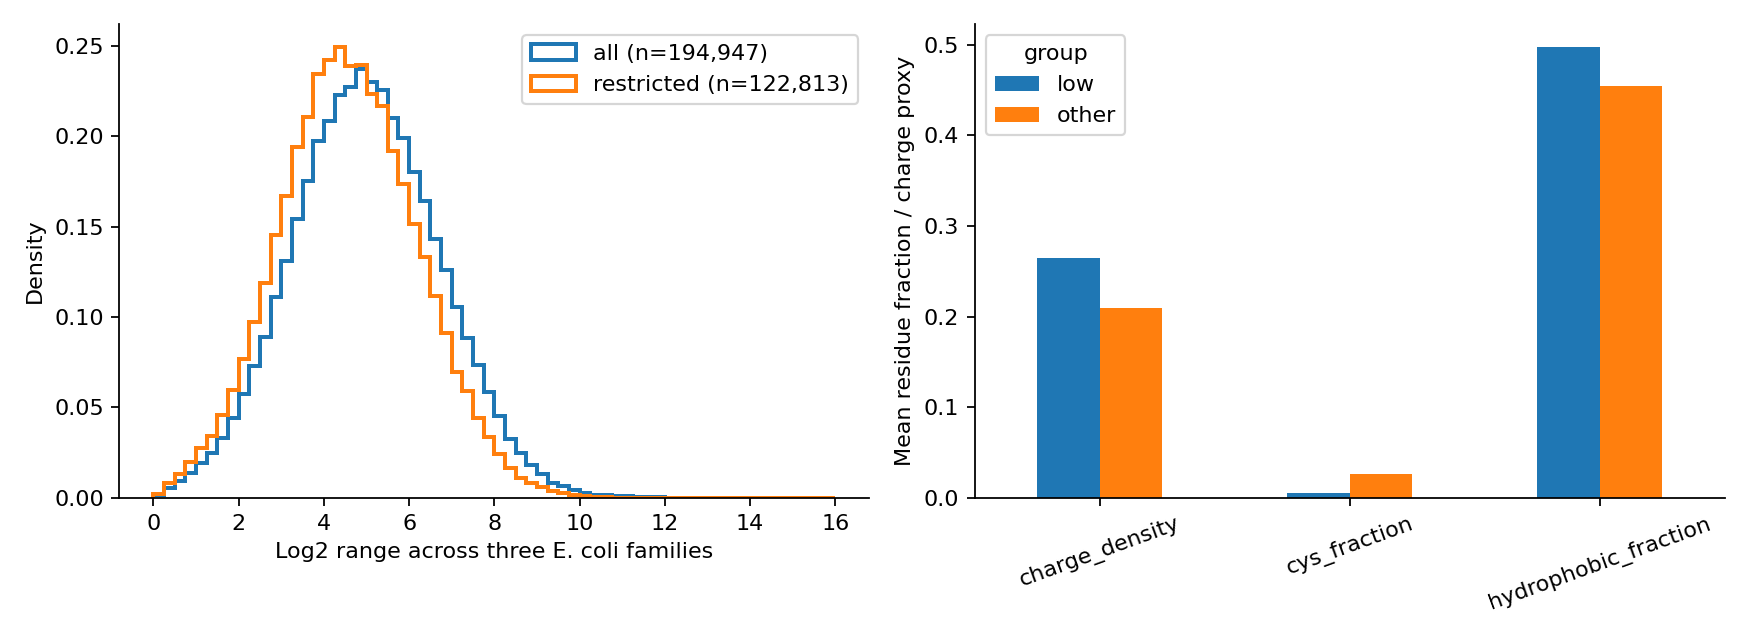

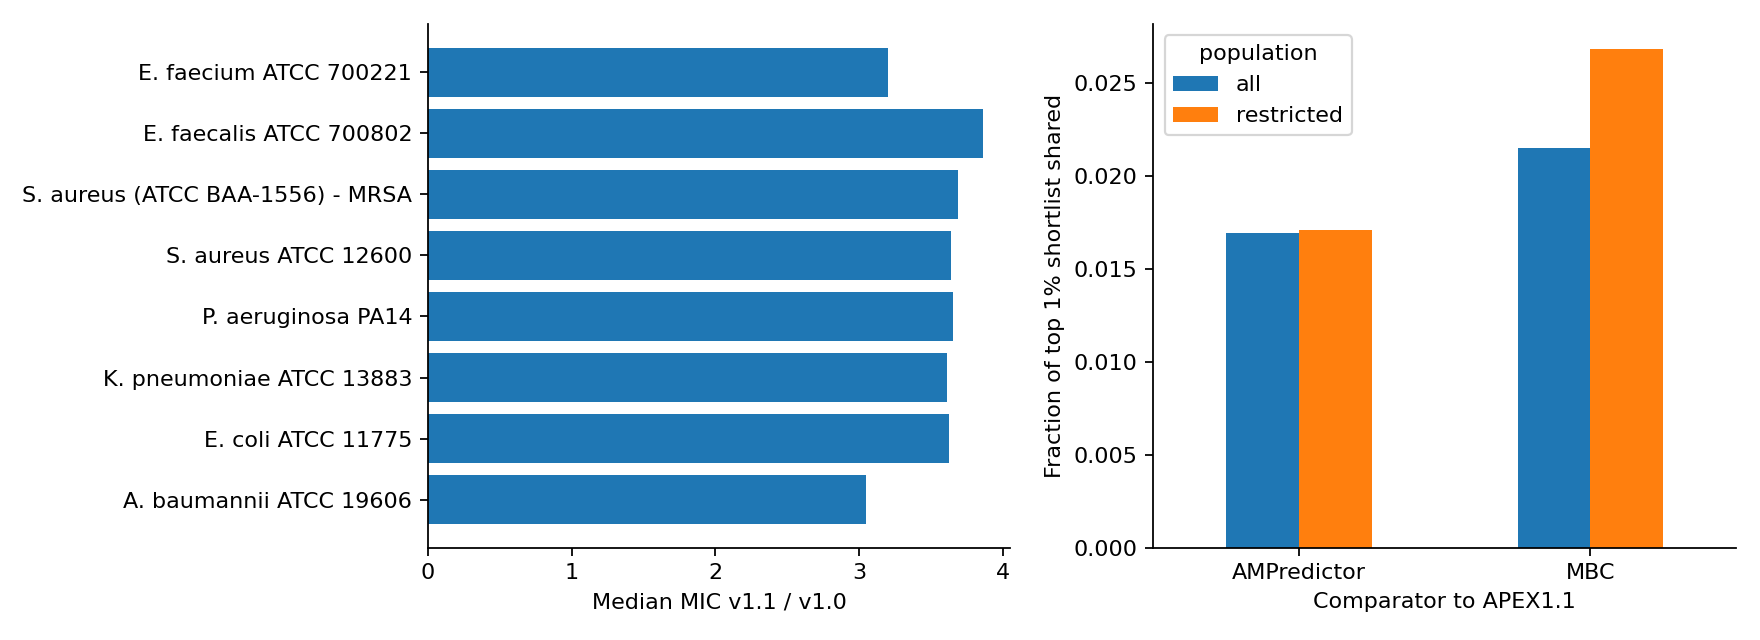

In [15]:
from pathlib import Path
from collections import Counter,defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
O=Path('analysis_outputs');O.mkdir(exist_ok=True)
d=pd.read_csv('df_damp_195625x57.tsv',sep='\t').set_index('sequence')
src=pd.read_csv('scratchpad/source_sequences.tsv',sep='\t').set_index('sequence').source
mapping={'APEX1.0':'apex_1_0_E._coli_ATCC11775','APEX1.1':'apex_1_1_E._coli_ATCC_11775','MBC':'mbc_attention_E._coli_unspecified_strain','AMPredictor':'ampredictor_E._coli_unspecified_strain'}
v=d[list(mapping.values())].rename(columns={b:a for a,b in mapping.items()}).dropna();z=np.log2(v)
s=v.index.to_series();f=pd.DataFrame(index=v.index)
f['length']=s.str.len();f['charge_density']=(s.str.count('[KR]')-s.str.count('[DE]'))/f.length
f['hydrophobic_fraction']=s.str.count('[AILMFWVY]')/f.length;f['cys_fraction']=s.str.count('C')/f.length
f['entropy_bits']=[-sum((n/len(seq))*np.log2(n/len(seq)) for n in Counter(seq).values()) for seq in s]
f['source']=src.reindex(f.index)
# Restriction is informed by the published AMPredictor training set, not a proven applicability domain.
domain=f.length.between(8,39)&f.cys_fraction.eq(0)
summary=[];feature_rows=[];match_rows=[];low_sets={};source_rows=[]
sets={'four_outputs':list(z),'three_families':['APEX1.1','MBC','AMPredictor'],'MBC_AMPredictor':['MBC','AMPredictor'],'APEX_same_strain':['APEX1.0','APEX1.1']}
features=['length','charge_density','hydrophobic_fraction','cys_fraction','entropy_bits']
for population,mask in [('all',pd.Series(True,index=f.index)),('restricted',domain)]:
 for comparison,cols in sets.items():
    a=z.loc[mask,cols];r=a.max(axis=1)-a.min(axis=1);cut=r.quantile(.05);low=r.index[r.le(cut)];other=r.index[r.gt(cut)]
    low_sets[(population,comparison)]=set(low)
    med=a.median(axis=1)
    summary.append({'population':population,'comparison':comparison,'n':len(a),'low_n':len(low),'low_5pct_max_log2_range':cut,'median_log2_range':r.median(),'within_twofold_fraction':r.le(1).mean(),'low_median_MIC_uM':2**med.loc[low].median(),'other_median_MIC_uM':2**med.loc[other].median()})
    for group,idx in [('low',low),('other',other)]:
      for feature in features:
       feature_rows.append({'population':population,'comparison':comparison,'group':group,'feature':feature,'median':f.loc[idx,feature].median(),'mean':f.loc[idx,feature].mean()})
    if comparison=='three_families':
      for source in f.source.unique():
       ix=f.index[mask&f.source.eq(source)];source_rows.append({'population':population,'source':source,'n':len(ix),'low_fraction':len(set(ix)&set(low))/len(ix) if len(ix) else np.nan})
      # Paired descriptive contrasts, matching source, exact length and 1-log2 median-MIC bins.
      pools=defaultdict(list);rng=np.random.default_rng(20261022)
      for seq in other: pools[(f.at[seq,'source'],f.at[seq,'length'],int(np.floor(med[seq])))].append(seq)
      matched=[]
      for seq in rng.permutation(low):
       pool=pools[(f.at[seq,'source'],f.at[seq,'length'],int(np.floor(med[seq])))]
       if pool: matched.append((seq,pool.pop(int(rng.integers(len(pool))))))
      for feat in features:
       delta=[f.at[x,feat]-f.at[y,feat] for x,y in matched]
       match_rows.append({'population':population,'feature':feat,'matched_pairs':len(matched),'low_total':len(low),'mean_paired_difference':np.mean(delta),'median_paired_difference':np.median(delta)})
      pd.DataFrame(matched,columns=['low_sequence','control_sequence']).to_csv(O/f'low_disagreement_matches_{population}.csv',index=False)
      f.loc[low].join(v.loc[low]).assign(log2_range=r.loc[low]).to_csv(O/f'low_disagreement_sequences_{population}.csv')
summary=pd.DataFrame(summary);summary.to_csv(O/'low_disagreement_summary.csv',index=False)
fr=pd.DataFrame(feature_rows);fr.to_csv(O/'low_disagreement_features.csv',index=False)
mr=pd.DataFrame(match_rows);mr.to_csv(O/'low_disagreement_matched.csv',index=False)
pd.DataFrame(source_rows).to_csv(O/'low_disagreement_by_source.csv',index=False)
print(summary.to_string(index=False));print(mr.to_string(index=False))
print(fr[(fr.population=='all')&(fr.comparison=='three_families')].to_string(index=False))
# Re-estimate strongest model disagreement claims on the restricted population.
from itertools import combinations
rows=[]
for pop,mask in [('all',pd.Series(True,index=f.index)),('restricted',domain)]:
 a=z.loc[mask].sort_index();k=int(np.ceil(len(a)*.01))
 for l,r in combinations(a,2):
  delta=a[r]-a[l]
  rows.append({'population':pop,'left':l,'right':r,'n':len(a),'spearman':a[l].corr(a[r],method='spearman'),'median_log2_ratio':delta.median(),'within_twofold':delta.abs().le(1).mean(),'top1pct_overlap':len(set(a[l].nsmallest(k).index)&set(a[r].nsmallest(k).index))/k})
pd.DataFrame(rows).to_csv(O/'domain_restricted_agreement.csv',index=False);print(pd.DataFrame(rows).to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for pop,mask in [('all',pd.Series(True,index=f.index)),('restricted',domain)]:
 a=z.loc[mask,['APEX1.1','MBC','AMPredictor']];r=a.max(axis=1)-a.min(axis=1)
 ax[0].hist(r,bins=np.linspace(0,16,65),density=True,histtype='step',label=f'{pop} (n={len(r):,})',linewidth=1.8)
ax[0].set(xlabel='Log2 range across three E. coli families',ylabel='Density');ax[0].legend()
g=fr[(fr.population=='all')&(fr.comparison=='three_families')&(fr.feature.isin(['charge_density','hydrophobic_fraction','cys_fraction']))]
g.pivot(index='feature',columns='group',values='mean').plot.bar(ax=ax[1]);ax[1].set(ylabel='Mean residue fraction / charge proxy',xlabel='');ax[1].tick_params(axis='x',rotation=20)
fig.tight_layout();fig.savefig(O/'low_disagreement_profiles.png',dpi=160);plt.close()
fig,axs=plt.subplots(1,2,figsize=(11,4))
ver=pd.read_csv(O/'apex_versions.csv');ver=ver[~ver.alias_unverified]
axs[0].barh(ver.target.str.replace('vancomycin-resistant ','',regex=False),ver.median_fold_ratio);axs[0].set_xlabel('Median MIC v1.1 / v1.0')
r=pd.DataFrame(rows);g=r[r.left.eq('APEX1.1')].pivot(index='right',columns='population',values='top1pct_overlap');g.plot.bar(ax=axs[1]);axs[1].set(ylabel='Fraction of top 1% shortlist shared',xlabel='Comparator to APEX1.1');axs[1].tick_params(axis='x',rotation=0)
fig.tight_layout();fig.savefig(O/'audit_disagreement_summary.png',dpi=160);plt.close()

from IPython.display import Image, display
display(Image(filename=str(O/'low_disagreement_profiles.png')))
display(Image(filename=str(O/'audit_disagreement_summary.png')))


**Interpretation.** The bottom 5% three-family set has median length 14 versus 24 residues and higher mean charge proxy, lower cysteine fraction, and lower composition entropy. Hydrophobic enrichment largely disappears after matching; a smaller charge difference and lower entropy remain. The largest allowed fold spread in this lower tail is still about 4.63, so “low disagreement” is relative. Only 0.758% of complete cases have all three predictions within twofold. Low disagreement does not imply low predicted MIC or accuracy.

The restricted cohort contains 122,813 sequences. Poor APEX-versus-other-family shortlist overlap persists (about 1.6–2.7%), although MBC–AMPredictor overlap rises from 5.49% to 13.0%. Thus, the documented sequence-domain mismatch explains neither the full extent nor every form of disagreement. These analyses assess computational comparability, not matched-assay calibration. Priorities are export/inference replay, strain-and-assay-matched experimental labels, family-aware validation, and determining whether agreement predicts measured error.

## 17. Pinned-weight replay and preprocessing sensitivity

Replay all four DeepAMP SavedModels on 32 seeded random eligible sequences and eight extreme predictions (40 unique sequences). Compare two preprocessing paths present in the pinned repository: zero padding in `predict.py` versus explicitly encoded `-` padding in `code/utils.py`/`benchmark_utils.py`. Both share the same amino-acid channel order. Use exported TensorFlow serving signatures to avoid changing weights. Report log2 replay/TSV ratios and hash downloaded weights. This checks a sampled export and a preprocessing discrepancy; it does not reproduce every TSV entry or every model family.

The isolated replay interpreter uses installed TensorFlow 2.19.0 plus protobuf 4.25.8 and tf-keras 2.19.0. Dependencies and weights were cached during this investigation; the subprocess below needs that environment. Other analyses use the notebook environment.

**Rationale — distinguish an inference-route problem from model behavior.** The same saved weights can give different outputs under different padding conventions. A log2 replay/TSV ratio of zero means numerical reproduction; an absolute ratio of one means a twofold difference. The selected 40-sequence replay tests the sampled export path only. Agreement with saved values is not agreement with measured MIC, and the selected extremes do not estimate a population failure rate.

In [16]:
import subprocess
subprocess.run(['scratchpad/replay/venv/bin/python','scratchpad/replay_deepamp.py'],check=True)
display(pd.read_csv('analysis_outputs/deepamp_replay_summary.csv'))

                            n        median   max_abs    median_abs
variant     padding                                                
CNN_gr_neg  token_padding  40 -1.117363e-08  0.000003  1.624970e-07
            zero_padding   40 -2.779896e-02  7.065907  9.369866e-02
CNN_gr_pos  token_padding  40 -8.372285e-09  0.000002  1.258165e-07
            zero_padding   40 -1.047468e-02  5.365634  2.994817e-01
LSTM_gr_neg token_padding  40  3.218472e-08  0.000003  5.807523e-07
            zero_padding   40  1.340889e-01  1.904559  4.961370e-01
LSTM_gr_pos token_padding  40 -2.815914e-08  0.000006  7.383609e-07
            zero_padding   40  1.876679e-01  8.517663  2.644981e-01


,variant,padding,n,median,max_abs,median_abs
0,CNN_gr_neg,token_padding,40,-1.117363e-08,0.000003,1.624970e-07
1,CNN_gr_neg,zero_padding,40,-2.779896e-02,7.065907,9.369866e-02
2,CNN_gr_pos,token_padding,40,-8.372285e-09,0.000002,1.258165e-07
3,CNN_gr_pos,zero_padding,40,-1.047468e-02,5.365634,2.994817e-01
4,LSTM_gr_neg,token_padding,40,3.218472e-08,0.000003,5.807523e-07
5,LSTM_gr_neg,zero_padding,40,1.340889e-01,1.904559,4.961370e-01
6,LSTM_gr_pos,token_padding,40,-2.815914e-08,0.000006,7.383609e-07
7,LSTM_gr_pos,zero_padding,40,1.876679e-01,8.517663,2.644981e-01


## 18. Experimental labels, error association and family-held-out calibration diagnostic

Curate E. coli ATCC 11775 observations from the two cached de-extinction assay tables. Preserve the original entry, DOI, units, medium, inoculum and sequence match. Only numeric MICs enter the primary diagnostic; `N.A.` is unresolved and is neither imputed nor silently treated as >64 µM. Terminal chemistry is not independently resolved. The study describes LB, 20-hour exposure and 1–64 µM measurements ([methods](https://www.nature.com/articles/s41551-024-01201-x)).

Use exact sequence matching. Form conservative sequence-connected groups via >=80% equal-length identity or exact terminal containment covering >=80% of the longer sequence. Compute errors, disagreement–absolute-error associations, and leave-one-family-out median-offset calibration (fit offset only on remaining families). This grouping is a limited dependence sensitivity, not exhaustive homology detection. The sample is selected and small; training-corpus overlap must be checked before interpreting accuracy. The workbook has modified peptides and other strains; it is inventoried rather than silently merged as identical chemistry.

**Rationale — keep a small experimental diagnostic separate from an accuracy benchmark.** MAE is the mean absolute prediction–measurement difference; RMSE gives larger differences more weight by squaring before averaging and taking the square root. Log2 errors measure multiplicative separation. These values apply only to the matched numeric observations. Training-corpus overlap, unresolved chemistry, and excluded censored values prevent a general accuracy ranking; leaving families out of an offset fit cannot remove prior model exposure.

Assay audit: 67 matched sequences; 13 numeric E. coli observations; 12 families
      model  n  families  median_signed_log2_error  MAE_log2  within_twofold  spearman  disagreement_vs_absolute_error_rho  family_heldout_offset_MAE
    APEX1.0 13        12                 -0.615875  1.186366        0.461538 -0.192186                           -0.170330                   1.331658
    APEX1.1 13        12                 -0.060510  0.113469        1.000000  0.943456                            0.060440                   0.086983
        MBC 13        12                  0.106801  1.132767        0.615385  0.133948                            0.725275                   1.395992
AMPredictor 13        12                 -0.280371  1.419888        0.384615 -0.099005                            0.950549                   1.555399
                            MIC_uM  disagreement    APEX1.0    APEX1.1        MBC  AMPredictor
sequence                                                                   

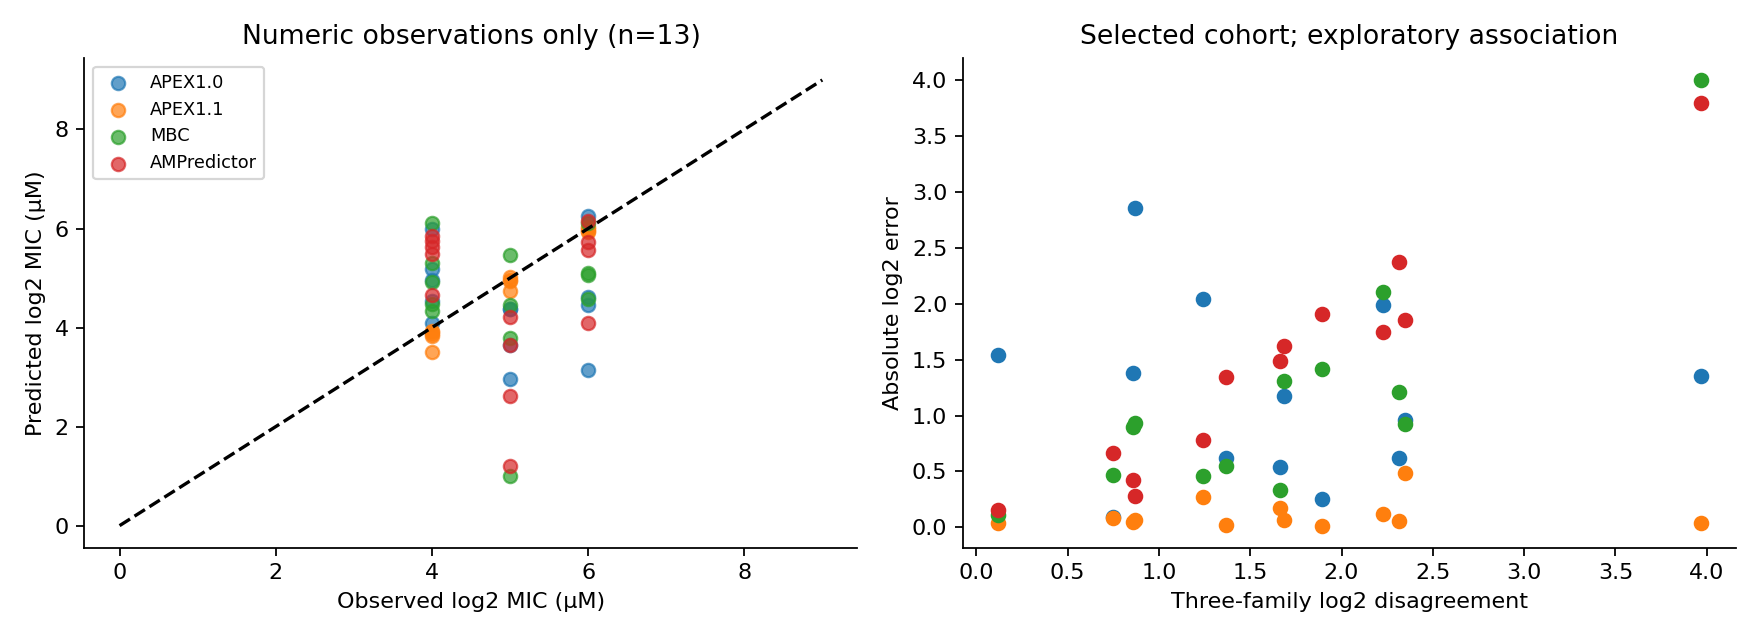

In [17]:
from pathlib import Path
from itertools import combinations
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
O=Path('analysis_outputs');d=pd.read_csv('df_damp_195625x57.tsv',sep='\t').set_index('sequence')
rows=[]
for name,sc in [('extinctome_assays_2.xlsx','Seq'),('extinctome_assays_3.xlsx','Sequence')]:
 a=pd.read_excel('scratchpad/DAMP/data/data_damp/raw/'+name,header=1,keep_default_na=False)
 for _,r in a.iterrows():
  s=r[sc].strip();val=pd.to_numeric(r['E. coli ATCC11775'],errors='coerce')
  rows.append({'sequence':s,'table':name,'raw_MIC':r['E. coli ATCC11775'],'MIC_uM':val,'in_TSV':s in d.index,'strain':'E. coli ATCC11775','unit':'uM','medium':'LB','exposure_h':20,'inoculum_cells_ml':2e6,'modification_status':'not independently resolved','doi':'10.1038/s41551-024-01201-x'})
a=pd.DataFrame(rows);a.to_csv(O/'experimental_label_audit.csv',index=False)
a=a[a.in_TSV].drop_duplicates('sequence').set_index('sequence')
cols=['apex_1_0_E._coli_ATCC11775','apex_1_1_E._coli_ATCC_11775','mbc_attention_E._coli_unspecified_strain','ampredictor_E._coli_unspecified_strain'];names=['APEX1.0','APEX1.1','MBC','AMPredictor']
v=d.loc[a.index,cols];v.columns=names;a=a.join(v)
# Families: transitive graph using >=80% global identity for equal-length pairs,
# or exact containment of at least 8 residues with >=80% length coverage.
seqs=list(a.index);parent={s:s for s in seqs}
def root(s):
 while parent[s]!=s:s=parent[s]
 return s
for s,t in combinations(seqs,2):
 identity=sum(x==y for x,y in zip(s,t))/len(s) if len(s)==len(t) else 0
 containment=(s in t or t in s) and min(len(s),len(t))>=8 and min(len(s),len(t))/max(len(s),len(t))>=.8
 if identity>=.8 or containment:parent[root(s)]=root(t)
a['family']=[root(s) for s in a.index]
# Numeric-only primary analysis. N.A. is preserved as unresolved, never imputed.
e=a.dropna(subset=['MIC_uM']+names).copy();e['log2_observed']=np.log2(e.MIC_uM)
e['disagreement']=np.log2(e[['APEX1.1','MBC','AMPredictor']]).max(axis=1)-np.log2(e[['APEX1.1','MBC','AMPredictor']]).min(axis=1)
metrics=[]
for m in names:
 e[m+'_error']=np.log2(e[m])-e.log2_observed
 # Leave-one-family-out intercept calibration; fit only on other families.
 calibrated=[]
 for s,r in e.iterrows():
  train=e[e.family!=r.family];offset=(train.log2_observed-np.log2(train[m])).median()
  calibrated.append(np.log2(r[m])+offset)
 e[m+'_calibrated_log2']=calibrated
 err=e[m+'_error'];ce=e[m+'_calibrated_log2']-e.log2_observed
 metrics.append({'model':m,'n':len(e),'families':e.family.nunique(),'median_signed_log2_error':err.median(),'MAE_log2':err.abs().mean(),'within_twofold':err.abs().le(1).mean(),'spearman':e[m].corr(e.MIC_uM,method='spearman'),'disagreement_vs_absolute_error_rho':e.disagreement.corr(err.abs(),method='spearman'),'family_heldout_offset_MAE':ce.abs().mean()})
e.to_csv(O/'experimental_ecoli_matched.csv');pd.DataFrame(metrics).to_csv(O/'experimental_metrics.csv',index=False)
# Audit workbook: retain chemical modification text; do not silently strip it to claim matches.
w=pd.read_excel('wet_lab_validated_amp_sources.xlsx',sheet_name='Assay records',header=3);w.to_csv(O/'workbook_assay_inventory.csv',index=False)
print('Assay audit:',len(a),'matched sequences;',len(e),'numeric E. coli observations;',e.family.nunique(),'families')
print(pd.DataFrame(metrics).to_string(index=False));print(e[['MIC_uM','disagreement']+names].to_string())
fig,ax=plt.subplots(1,2,figsize=(11,4))
for m in names:ax[0].scatter(e.log2_observed,np.log2(e[m]),label=m,alpha=.7)
ax[0].plot([0,9],[0,9],'k--');ax[0].set(xlabel='Observed log2 MIC (µM)',ylabel='Predicted log2 MIC (µM)',title=f'Numeric observations only (n={len(e)})');ax[0].legend(fontsize=8)
for m in names:ax[1].scatter(e.disagreement,e[m+'_error'].abs(),label=m)
ax[1].set(xlabel='Three-family log2 disagreement',ylabel='Absolute log2 error',title='Selected cohort; exploratory association')
fig.tight_layout();fig.savefig(O/'experimental_validation.png',dpi=160);plt.close()

from IPython.display import Image,display
display(Image(filename='analysis_outputs/experimental_validation.png'))

## 19. Training overlap and discordant-family audit

Download and inspect the pinned APEXDB corpus (including its CV/Ind labels) and AMPredictor training list. Count exact overlap with the TSV and with numeric experimental labels. For the largest extreme-disagreement family, report nearest equal-length ungapped identity to each corpus; this does not exclude different-length homologues. CV/Ind membership identifies development/evaluation exposure, not proof of which individual checkpoint trained on each peptide.

**Decisive limitation:** every one of the 13 matched numeric labels occurs in the APEX corpus. Eight are CV and five Ind. Therefore, no clean independent APEX validation cohort was established. One label differs between assay and corpus (16 versus 12 µM). These observations prohibit interpreting the small-sample accuracy or calibration result as external generalization. The files named archaeome assays 3/4 contain amino-acid composition comparison p-values, not MIC observations; the shortlist contains predicted MICs and was excluded from experimental validation.

**Rationale — check whether experimental labels are genuinely new to a model.** Exact overlap counts identify exposure to a development/evaluation corpus, not checkpoint-specific training membership. Equal-length ungapped identity is the fraction of matching residue positions; it misses gapped and different-length relationships. Low exact overlap therefore does not establish independence. AMPredictor's cysteine-free training composition also limits a biological interpretation of cysteine-rich extremes.

In [18]:
from pathlib import Path
import numpy as np,pandas as pd
O=Path('analysis_outputs');d=pd.read_csv('df_damp_195625x57.tsv',sep='\t').set_index('sequence')
t=pd.read_csv('scratchpad/replay/APEXDB.csv');t.Sequence=t.Sequence.str.strip()
e=pd.read_csv(O/'experimental_ecoli_matched.csv');r=e[['sequence','MIC_uM']].merge(t,left_on='sequence',right_on='Sequence');r[['sequence','MIC_uM','E. coli ATCC 11775','Group (APEX training)']].to_csv(O/'experimental_training_overlap.csv',index=False)
# Literal backslash-t separators in the pinned AMPredictor file.
lines=Path('scratchpad/replay/ampredictor_train.txt').read_text().splitlines();amp=set()
for line in lines:
 parts=line.replace('\\t','\t').split('\t')
 if len(parts)>=2:amp.add(parts[1].strip())
rows=[]
for name,seqs in [('APEX_CV',set(t.loc[t['Group (APEX training)'].eq('CV'),'Sequence'])),('APEX_Ind',set(t.loc[t['Group (APEX training)'].eq('Ind'),'Sequence'])),('AMPredictor_train',amp)]:
 rows.append({'corpus':name,'unique_corpus_sequences':len(seqs),'exact_TSV_overlap':len(set(d.index)&seqs),'numeric_assay_overlap':len(set(e.sequence)&seqs)})
pd.DataFrame(rows).to_csv(O/'training_overlap_counts.csv',index=False);print(pd.DataFrame(rows).to_string(index=False))
c=pd.read_csv(O/'extreme_sequence_components.csv');target=c.loc[c.component.eq(1),'sequence'];nearest=[]
for s in target:
 for name,seqs in [('APEX_corpus',set(t.Sequence)),('AMPredictor_train',amp)]:
  candidates=[q for q in seqs if len(q)==len(s)]
  if candidates:
   q=max(sorted(candidates),key=lambda q:sum(a==b for a,b in zip(s,q)))
   nearest.append({'sequence':s,'corpus':name,'nearest_equal_length_sequence':q,'ungapped_identity':sum(a==b for a,b in zip(s,q))/len(s),'has_cysteine':'C' in s})
pd.DataFrame(nearest).to_csv(O/'discordant_family_training_neighbors.csv',index=False)
print(pd.DataFrame(nearest).groupby('corpus').ungapped_identity.agg(['min','median','max']))


           corpus  unique_corpus_sequences  exact_TSV_overlap  numeric_assay_overlap
          APEX_CV                     1388                392                      8
         APEX_Ind                      348                 92                      5
AMPredictor_train                     2624               2597                      0
                        min    median       max
corpus                                         
AMPredictor_train  0.190476  0.238095  0.285714
APEX_corpus        0.142857  0.190476  0.238095


## Research outcome and unresolved work

DeepAMP token-padding replay agrees with the sampled TSV to <6.2e-6 log2 units. Zero padding can shift predictions by up to 8.52 log2 units in this selected sample; the TSV matches the token-padding path. This is a reproducibility trap, not evidence that the TSV used the wrong path.

The experimental diagnostic has 13 numeric E. coli observations from 12 conservative families. Error–disagreement associations are model-dependent and the APEX development overlap prevents independent confidence validation. Family-held-out offset fitting cannot undo prior model exposure. No model superiority or calibrated uncertainty claim follows.

Completed: a four-variant model replay; assay inventory and exact joins; family-sensitive error/calibration diagnostics; pinned training-overlap and local-family analysis. Outstanding: replay APEX/MBC/AMPredictor weights, obtain independent same-strain measured labels with chemical and censoring metadata, and perform calibration plus external evaluation on genuinely independent family/source partitions. The present evidence does not support promoting an ensemble or disagreement score into a validated confidence estimate.

## 20. Symmetric disagreement tails and alternative explanations

The code below compares bottom/top 5% three-family E. coli log2 ranges on identical complete cases. It reports low/middle/high composition profiles, matches high sequences to non-high controls and separately to low sequences by source, exact length and predicted-MIC bin, and records matching coverage. The cysteine-free length 8–39 sensitivity is repeated. Source-specific tails test whether pooled profile differences depend on collection composition.

Further angles quantify which model sets each prediction extreme, distinguish raw MIC-ratio disagreement from offset-centered and percentile-rank disagreement, compare AMP-classifier consensus, and downweight exact terminal-extension components. Centering is not experimental calibration, percentile ranks are dataset-relative, and classifier votes are not labels. Family weights use inverse component size in the complete-case population; they address observed terminal redundancy only. No significance tests or causal claims are made. Quantile tails are descriptive; ties are retained.

For the project, these checks identify which apparent sequence characteristics survive restricted comparisons and which definitions of disagreement answer different research questions. Direct high/low matching may have poor common support, so its denominator must accompany any interpretation.

**Rationale — challenge a simple high-versus-low disagreement story.** Both tails use the same eligible population, so their profiles can be compared under a stated definition. Raw log2 range measures a concentration ratio; centered range removes global offsets; percentile range measures relative placement. They select different peptides by design. Matching coverage is the share of target-tail sequences with an available control, and a low coverage limits extrapolation of the matched contrast.

population      n  low_max_log2  high_min_log2  low_max_fold  high_min_fold
       all 194947      2.211183       7.838967      4.630548     228.962432
restricted 122813      1.959311       7.300493      3.888761     157.640344
       population       n  median_log2_range  median_MIC_uM  cysteine_present_fraction  length_mean  length_median  length_family_weighted_mean  charge_density_mean  charge_density_median  charge_density_family_weighted_mean  hydrophobic_fraction_mean  hydrophobic_fraction_median  hydrophobic_fraction_family_weighted_mean  cys_fraction_mean  cys_fraction_median  cys_fraction_family_weighted_mean  entropy_bits_mean  entropy_bits_median  entropy_bits_family_weighted_mean
group                                                                                                                                                                                                                                                                                                     

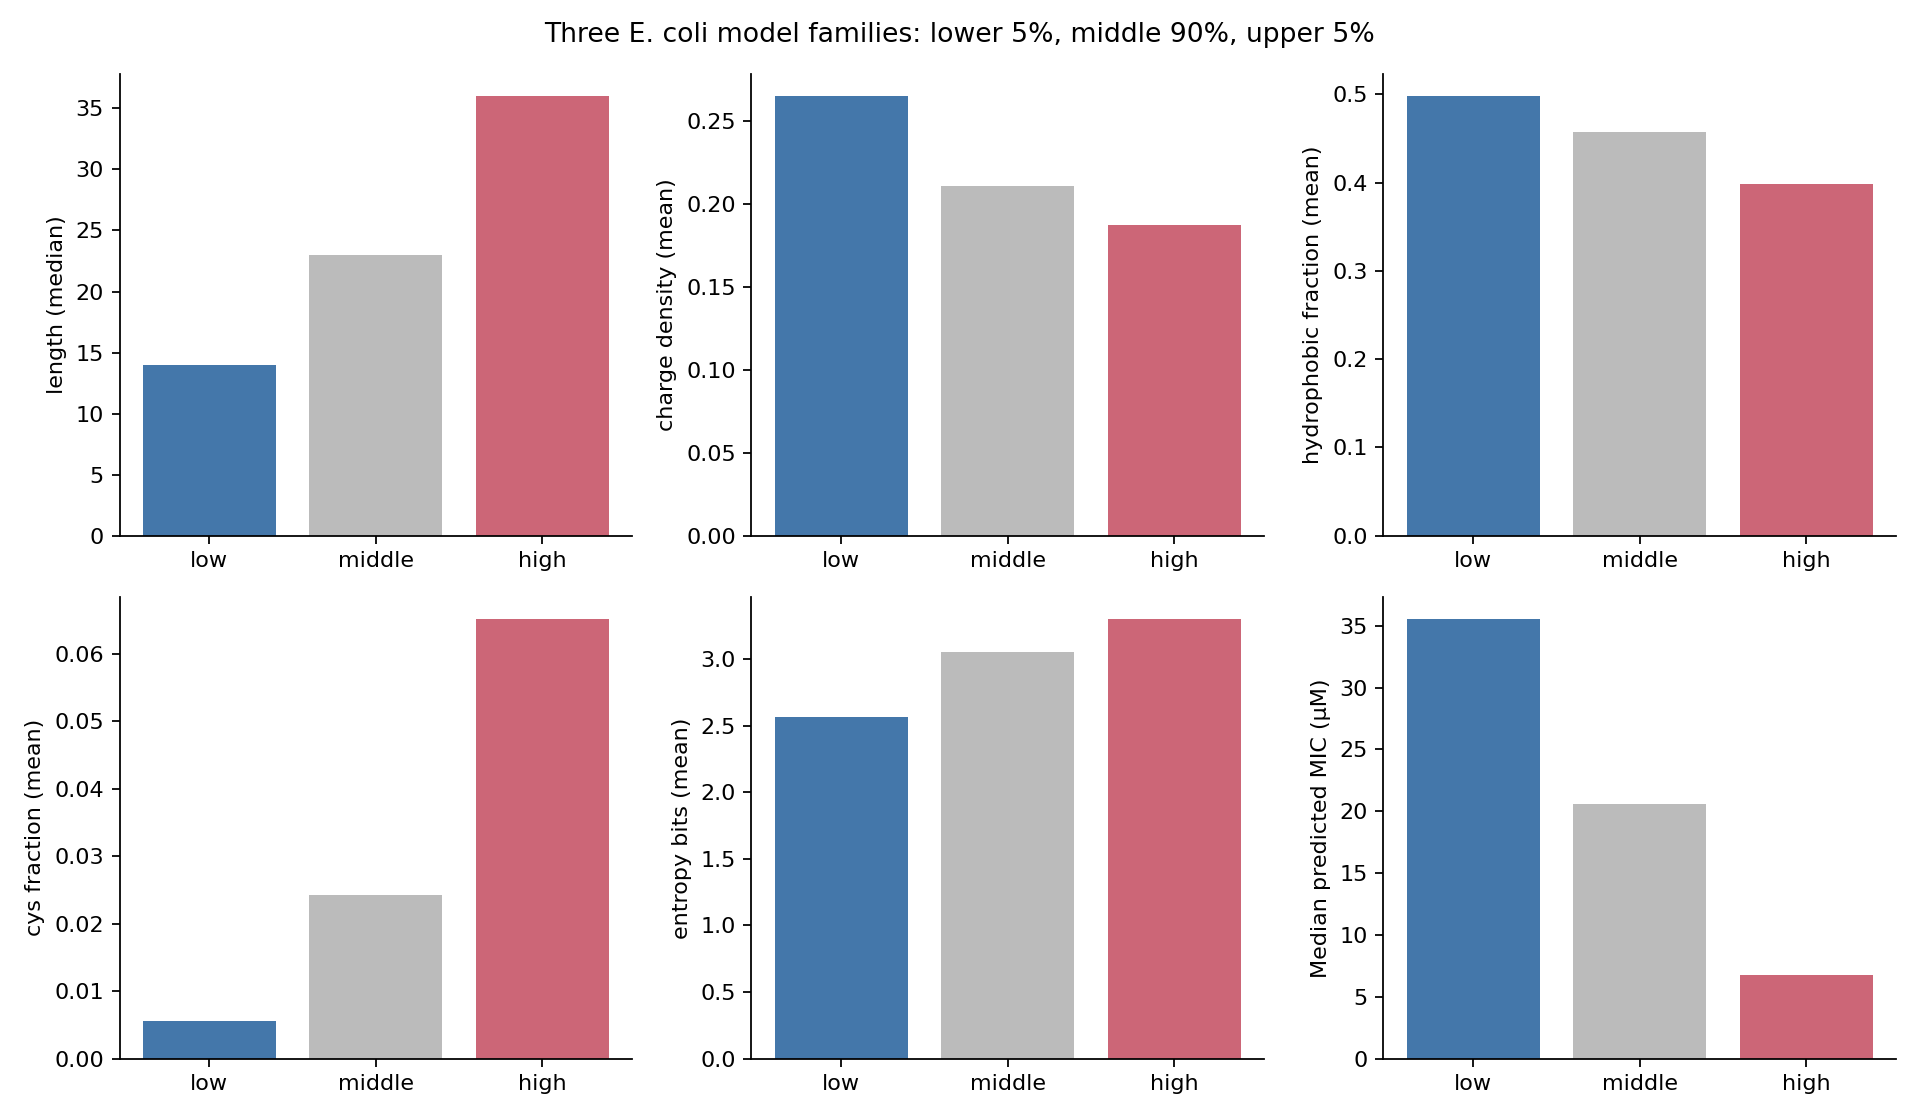

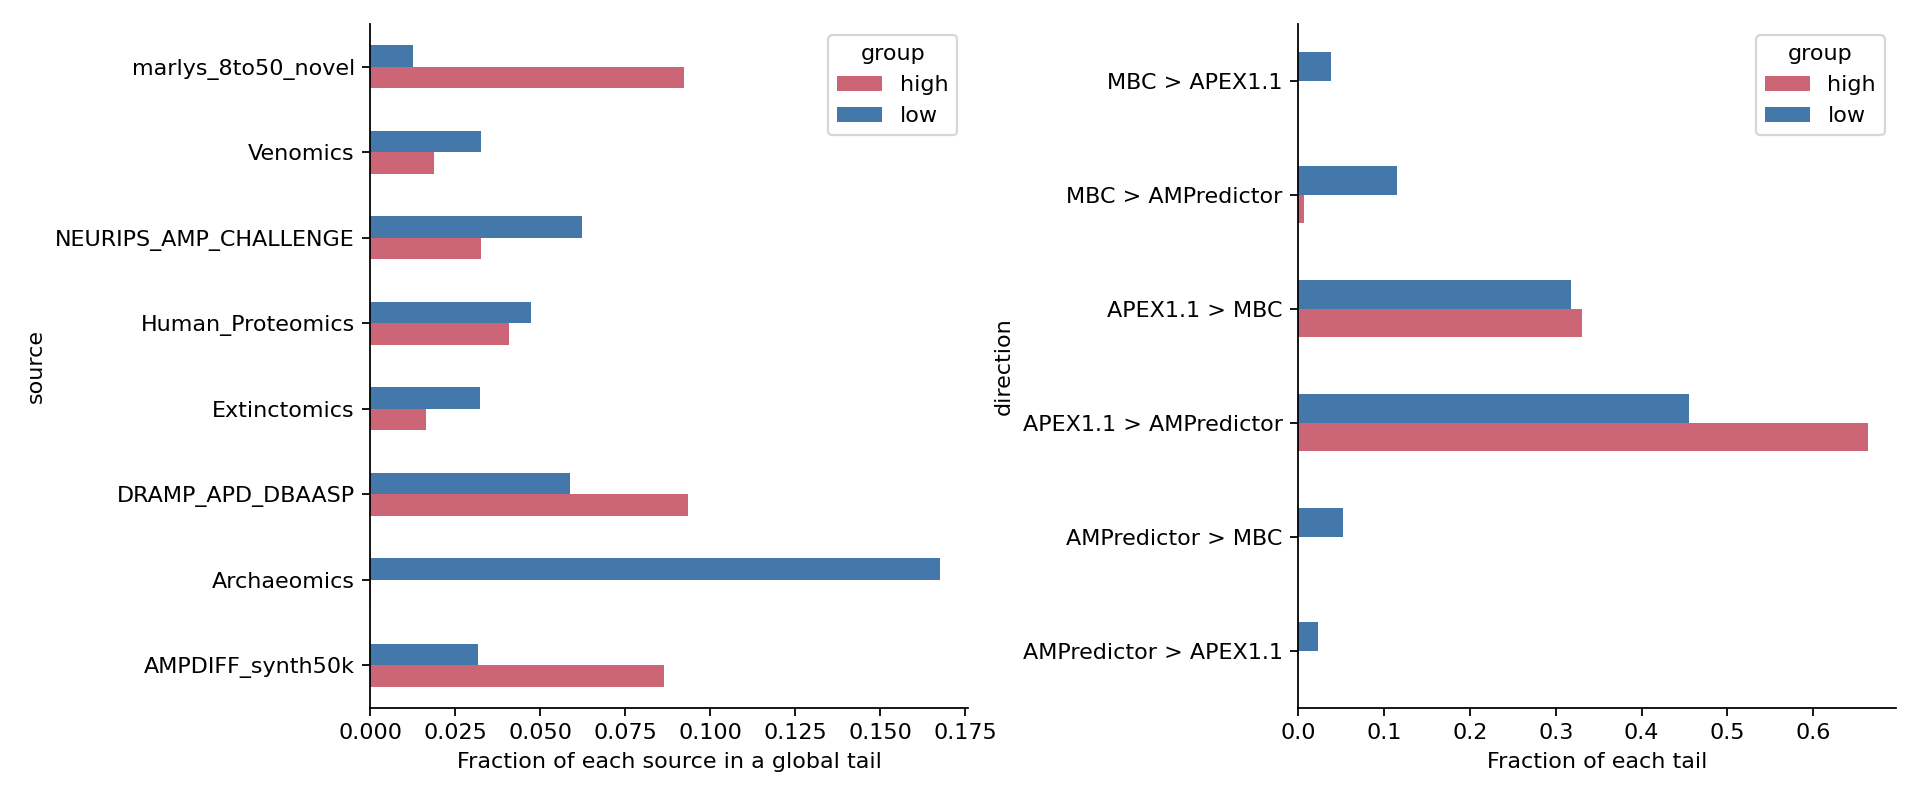

In [19]:
"""Symmetric tails, matched contrasts, model direction and dependence sensitivities."""
from pathlib import Path
from collections import Counter,defaultdict
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
O=Path('analysis_outputs');d=pd.read_csv('df_damp_195625x57.tsv',sep='\t').set_index('sequence')
sources=pd.read_csv('scratchpad/source_sequences.tsv',sep='\t').set_index('sequence').source
cols={'APEX1.1':'apex_1_1_E._coli_ATCC_11775','MBC':'mbc_attention_E._coli_unspecified_strain','AMPredictor':'ampredictor_E._coli_unspecified_strain'}
v=d[list(cols.values())].rename(columns={b:a for a,b in cols.items()}).dropna();z=np.log2(v)
s=v.index.to_series();f=pd.DataFrame(index=s.index);f['length']=s.str.len()
f['charge_density']=(s.str.count('[KR]')-s.str.count('[DE]'))/f.length
f['hydrophobic_fraction']=s.str.count('[AILMFWVY]')/f.length;f['cys_fraction']=s.str.count('C')/f.length
f['entropy_bits']=[-sum((n/len(q))*np.log2(n/len(q)) for n in Counter(q).values()) for q in s]
f['source']=sources.reindex(f.index);f['log2_range']=z.max(axis=1)-z.min(axis=1);f['median_log2_MIC']=z.median(axis=1)
features=['length','charge_density','hydrophobic_fraction','cys_fraction','entropy_bits']
# Connected components of observed exact terminal extensions: a limited dependence sensitivity.
parent={q:q for q in d.index}
def root(q):
 while parent[q]!=q:parent[q]=parent[parent[q]];q=parent[q]
 return q
for q in d.index:
 if len(q)<9:continue
 for t in [q[1:],q[:-1]]:
  if t in parent:parent[root(q)]=root(t)
f['terminal_family']=[root(q) for q in f.index]
f['family_weight']=1/f.groupby('terminal_family').terminal_family.transform('size')
thresholds=[];summaries=[];matched=[];source_stats=[];directions=[];sensitivity=[];within=[]
labels={}
for pop,mask in [('all',pd.Series(True,index=f.index)),('restricted',f.length.between(8,39)&f.cys_fraction.eq(0))]:
 a=f.loc[mask].copy();lo,hi=a.log2_range.quantile([.05,.95]);a['group']=np.select([a.log2_range.le(lo),a.log2_range.ge(hi)],['low','high'],default='middle');labels[pop]=a.group
 thresholds.append({'population':pop,'n':len(a),'low_max_log2':lo,'high_min_log2':hi,'low_max_fold':2**lo,'high_min_fold':2**hi})
 for group,b in a.groupby('group'):
  rec={'population':pop,'group':group,'n':len(b),'median_log2_range':b.log2_range.median(),'median_MIC_uM':2**b.median_log2_MIC.median(),'cysteine_present_fraction':b.cys_fraction.gt(0).mean()}
  for feat in features:
   rec[feat+'_mean']=b[feat].mean();rec[feat+'_median']=b[feat].median();rec[feat+'_family_weighted_mean']=np.average(b[feat],weights=b.family_weight)
  summaries.append(rec)
  zz=z.loc[b.index];pair=zz.idxmax(axis=1)+' > '+zz.idxmin(axis=1)
  for name,count in pair.value_counts().items():directions.append({'population':pop,'group':group,'direction':name,'n':count,'fraction':count/len(b)})
  for source,g in b.groupby('source'):
   source_stats.append({'population':pop,'group':group,'source':source,'n':len(g),'fraction_of_group':len(g)/len(b),'fraction_of_source':len(g)/a.source.eq(source).sum()})
 # High versus remaining sequences, and direct high-versus-low controls.
 for contrast,control in [('high_vs_rest',a[a.group!='high']),('high_vs_low',a[a.group=='low'])]:
  pools=defaultdict(list);rng=np.random.default_rng(20261023)
  for q,r in control.iterrows():pools[(r.source,r.length,int(np.floor(r.median_log2_MIC)))].append(q)
  pairs=[]
  for q in rng.permutation(a.index[a.group.eq('high')]):
   r=a.loc[q];pool=pools[(r.source,r.length,int(np.floor(r.median_log2_MIC)))]
   if pool:pairs.append((q,pool.pop(int(rng.integers(len(pool))))))
  pd.DataFrame(pairs,columns=['high_sequence','control_sequence']).to_csv(O/f'{pop}_{contrast}_matches.csv',index=False)
  for feat in features:
   delta=np.array([a.at[q,feat]-a.at[t,feat] for q,t in pairs]);matched.append({'population':pop,'contrast':contrast,'feature':feat,'n_pairs':len(pairs),'high_n':a.group.eq('high').sum(),'mean_paired_difference':delta.mean() if len(delta) else np.nan,'median_paired_difference':np.median(delta) if len(delta) else np.nan})
 # Rank spread is invariant to monotonic rescaling; centering removes global offsets only.
 zz=z.loc[a.index];centered=zz-zz.median();cr=centered.max(axis=1)-centered.min(axis=1)
 ranks=zz.rank(pct=True);rr=ranks.max(axis=1)-ranks.min(axis=1)
 raw_high=set(a.index[a.group.eq('high')]);raw_low=set(a.index[a.group.eq('low')])
 for name,score in [('offset_centered',cr),('percentile_rank_range',rr)]:
  h=set(score.index[score.ge(score.quantile(.95))]);l=set(score.index[score.le(score.quantile(.05))])
  sensitivity.append({'population':pop,'definition':name,'high_retention':len(h&raw_high)/len(raw_high),'low_retention':len(l&raw_low)/len(raw_low),'spearman_with_raw':score.corr(a.log2_range,method='spearman')})
 # Equal tail fractions within each collection remove unequal source representation.
 for source,b in a.groupby('source'):
  l,h=b.log2_range.quantile([.05,.95]);low=b[b.log2_range.le(l)];high=b[b.log2_range.ge(h)]
  for feat in features:within.append({'population':pop,'source':source,'feature':feat,'n_low':len(low),'n_high':len(high),'mean_high_minus_low':high[feat].mean()-low[feat].mean()})
 f.loc[a.index].assign(group=a.group).join(v).to_csv(O/f'high_low_sequences_{pop}.csv')
for name,obj in [('high_low_thresholds',thresholds),('high_low_profiles',summaries),('high_low_matched',matched),('high_low_sources',source_stats),('high_low_model_direction',directions),('high_low_definition_sensitivity',sensitivity),('high_low_within_source',within)]:pd.DataFrame(obj).to_csv(O/(name+'.csv'),index=False)
# Classifier agreement is an independent output type, not experimental validation.
cc=['macrel_general_AMP','ai4amp_general_AMP','amp_clip_general_AMP','amplify_general_AMP']
c=d.loc[f.index,cc].dropna();votes=c.ge(.5).sum(axis=1);classification=[]
for group in ['low','middle','high']:
 idx=labels['all'].index[labels['all'].eq(group)].intersection(c.index);vv=votes.loc[idx]
 classification.append({'group':group,'n':len(idx),'all_positive':vv.eq(4).mean(),'all_negative':vv.eq(0).mean(),'mixed':vv.between(1,3).mean()})
pd.DataFrame(classification).to_csv(O/'high_low_classifier_agreement.csv',index=False)
# Compact publication-style panels; units and definitions appear on every axis.
S=pd.DataFrame(summaries);P=S[S.population=='all'].set_index('group').loc[['low','middle','high']]
fig,axs=plt.subplots(2,3,figsize=(12,7));colors=['#4477AA','#BBBBBB','#CC6677']
for ax,feat in zip(axs.flat,features+['median_log2_MIC']):
 if feat=='median_log2_MIC':ys=P.median_MIC_uM;label='Median predicted MIC (µM)'
 else:ys=P[feat+('_median' if feat=='length' else '_mean')];label=feat.replace('_',' ')+(' (median)' if feat=='length' else ' (mean)')
 ax.bar(P.index,ys,color=colors);ax.set_ylabel(label)
fig.suptitle('Three E. coli model families: lower 5%, middle 90%, upper 5%');fig.tight_layout();fig.savefig(O/'high_low_profiles.png',dpi=160);plt.close()
fig,axs=plt.subplots(1,2,figsize=(12,5));ss=pd.DataFrame(source_stats);g=ss[(ss.population=='all')&ss.group.isin(['low','high'])].pivot(index='source',columns='group',values='fraction_of_source');g.plot.barh(ax=axs[0],color={'low':'#4477AA','high':'#CC6677'});axs[0].set_xlabel('Fraction of each source in a global tail')
dd=pd.DataFrame(directions);g=dd[(dd.population=='all')&dd.group.isin(['low','high'])].pivot(index='direction',columns='group',values='fraction').fillna(0);g.plot.barh(ax=axs[1],color={'low':'#4477AA','high':'#CC6677'});axs[1].set_xlabel('Fraction of each tail');fig.tight_layout();fig.savefig(O/'high_low_sources_drivers.png',dpi=160);plt.close()
print(pd.DataFrame(thresholds).to_string(index=False));print(P.to_string());print(pd.DataFrame(matched).to_string(index=False));print(pd.DataFrame(sensitivity).to_string(index=False));print(pd.DataFrame(classification).to_string(index=False))

from IPython.display import display,Image
display(Image(filename=str(O/'high_low_profiles.png')))
display(Image(filename=str(O/'high_low_sources_drivers.png')))


**Interpretation.** The high tail has median length 36 versus 14 and cysteine presence 56.4% versus 5.1%. High versus non-high matching attenuates charge, hydrophobicity and entropy differences. Only 1,019 direct high/low pairs can be matched, so that contrast represents a small subset. Length and entropy differences retain their direction within all eight source collections; charge does not.

APEX1.1 is the numerical maximum for 99.34% of high-tail sequences. Only 29.2% remain high by percentile-rank disagreement. These results distinguish directional scale disagreement from disagreement about prioritization. Classification consensus is associated with the tails but does not independently validate them. See [the final report](reports/FINAL_ANALYSIS.md) for supported conclusions, hypotheses and discriminating next studies.

## 21. MIC variability: repeatability versus condition differences

MIC is conditional on strain, peptide chemistry and assay conditions. Cross-model
spread cannot be equated with experimental noise or model error. The code below
recomputes three-family log2 ranges across several illustrative tolerances, before
and after cohort-wide model median centering. Centering diagnoses global offsets;
it is not calibration and the tolerances are not validated error allowances.

It also compares positive numeric APEXDB labels for identical sequences across
five within-species strain pairs. Nonnumeric/inactive labels remain excluded, since
their censoring limits were not independently established. These selected measured
contrasts are neither technical replicates nor independent APEX validation.

For the project, this separates numerical disagreement from the question of
whether models target the same experiment. It motivates replicated, crossed
peptide–strain–condition assays. [Evidence and design](reports/02_concentration_rules.md)
distinguish published AMP condition effects from hypotheses about these models.


**Rationale — separate prediction spread from assay variability.** A tolerance fraction counts peptides whose largest/smallest predicted MIC is within a chosen ratio. Median centering subtracts each model's typical log prediction; it changes numerical spread but preserves rankings and is not calibration against measurements. Ratios between recorded strain labels combine possible strain, assay, and reporting differences. They are not technical replicate noise and cannot supply a universal acceptable model-error band.

{
  "n": 194947,
  "excluded": 678,
  "median_raw_fold_spread": 31.223783432053743,
  "median_centered_fold_spread": 4.165047892268092,
  "centering_medians_log2_uM": {
    "apex_1_1_E._coli_ATCC_11775": 8.199452639575664,
    "mbc_attention_E._coli_unspecified_strain": 3.9168657875504844,
    "ampredictor_E._coli_unspecified_strain": 3.251187804030096
  }
}
 maximum_fold_spread  raw_fraction  centered_fraction      n
                   2      0.007582           0.148210 194947
                   4      0.038015           0.480028 194947
                   8      0.120448           0.770020 194947
                  16      0.284718           0.917839 194947
                  32      0.508487           0.973716 194947
                  64      0.724448           0.992306 194947
                 128      0.877700           0.997994 194947
                 256      0.959163           0.999492 194947
            strain_a                       strain_b   n  excluded_from_1736  median_absolu

,maximum_fold_spread,raw_fraction,centered_fraction,n
0,2,0.007582,0.148210,194947
1,4,0.038015,0.480028,194947
2,8,0.120448,0.770020,194947
3,16,0.284718,0.917839,194947
4,32,0.508487,0.973716,194947
5,64,0.724448,0.992306,194947
6,128,0.877700,0.997994,194947
7,256,0.959163,0.999492,194947


,strain_a,strain_b,n,excluded_from_1736,median_absolute_fold_ratio,p90_absolute_fold_ratio,fraction_within_twofold,fraction_over_fourfold,median_signed_log2_b_minus_a
0,E. coli ATCC 11775,E. coli AIC221,402,1334,2.0,8.00000,0.606965,0.164179,0.0
1,E. coli ATCC 11775,E. coli AIC222 - CRE,401,1335,2.0,4.00641,0.738155,0.107232,0.0
2,E. coli AIC221,E. coli AIC222 - CRE,505,1231,2.0,4.00000,0.817822,0.059406,0.0
3,P. aeruginosa PAO1,P. aeruginosa PA14,349,1387,1.0,4.00000,0.799427,0.071633,0.0
4,S. aureus ATCC 12600,S. aureus ATCC BAA-1556 - MRSA,152,1584,2.0,4.00000,0.815789,0.065789,0.0


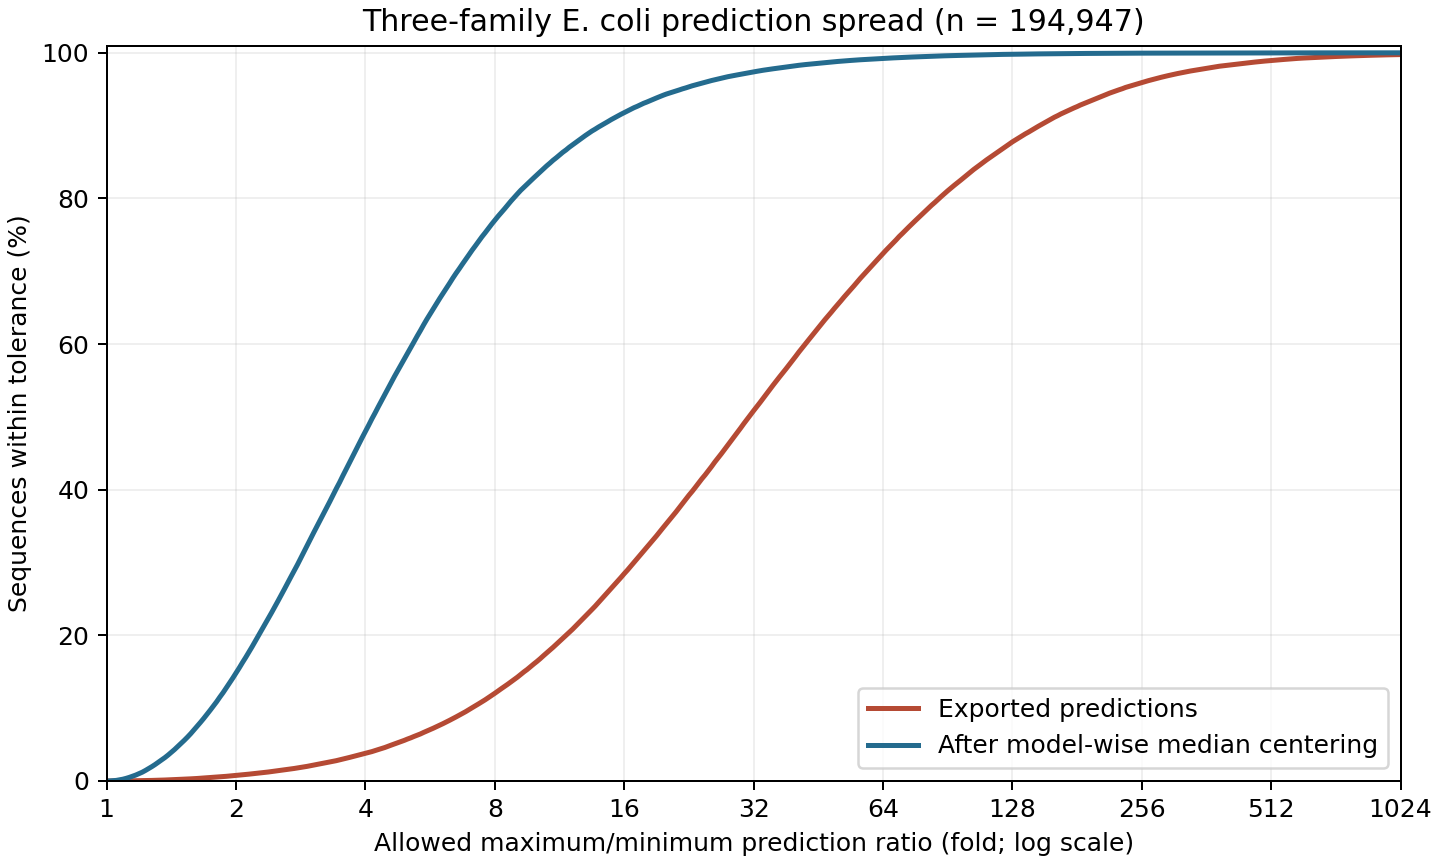

In [1]:
from pathlib import Path
import runpy
from IPython.display import Image, display

# Execute reproducible analysis; all inputs are local and outputs are descriptive.
mic_variability = runpy.run_path('scratchpad/mic_variability.py')
display(mic_variability['tolerances'])
display(mic_variability['strain'])
display(Image(filename='analysis_outputs/mic_variability_tolerance.png'))


**Interpretation.** Median
prediction spread falls from 31.22-fold to 4.17-fold after global median centering;
the fraction within fourfold rises from 3.80% to 48.00%. These changes demonstrate
offset sensitivity, not a fraction explained by assay variability. The 402 paired
numeric E. coli ATCC 11775/AIC221 labels have a median twofold ratio; 16.4% differ
by more than fourfold. Strain, assay and reporting effects cannot be separated
from these selected labels. Excluded nonnumeric observations limit generalization.

High disagreement may reflect omitted conditions or chemistry as well as model
limitations. Low disagreement does not establish experimental robustness. The
TSV contains no condition-matched replicates from which to estimate an experimental
variance baseline. A universal ±1 dilution allowance is therefore unwarranted.
This standalone section was executed independently; earlier outputs are retained.


## 22. Current extensions: overlap of fixed-budget lists

**Why add the UpSet analysis?** Pairwise counts omit whether the same peptide appears in all three lists. Exact membership partitions the union into disjoint groups and makes the choice of model visible. Each list uses 1,950 of the same 194,947 sequences; inclusive pairwise counts include triple-shared entries, while an exclusive bar does not.

The reviewed result is six peptides shared by all three and 5,674 selected by at least one. A shared fraction uses list size as its denominator; an intersection-over-union fraction would answer a different question. A uniform positive scaling of a model's outputs cannot change the list, so global scale offsets alone cannot explain its membership.

This extension is implemented outside the original code cells: [plot_shortlist_upset.py](analysis_review/plot_shortlist_upset.py), UpSet figure, [membership data](analysis_review/outputs/shortlist_overlap/shortlist_membership.csv), and [checks](analysis_review/outputs/shortlist_overlap/manifest.json).

![UpSet figure](analysis_review/outputs/shortlist_overlap/shortlist_upset.png)

## 23. Current extensions: cutoff decisions and their denominators

**Why add another decision rule?** A fixed list size and a fixed concentration cutoff can give very different candidate pools. Pass means only prediction ≤ the chosen cutoff. Pass/fail disagreement means exactly one tool passes a sequence, divided by all shared eligible sequences. Selected-pool disagreement instead uses only sequences passing at least one tool.

This denominator distinction explains how the APEX versions can agree on 98.68% overall while disagreeing on 77.84% of the selected pool at 16 µM. Both are model-decision summaries, not percentages of correct biological predictions. The later script separates the three-tool E. coli cohort, same-strain APEX pairs, within-head DeepAMP pairs, and general AMP voting.

The [decision script](analysis_review/screening_decision_trends.py), cutoff plot, and [decision tables](analysis_review/outputs/screening_decision_trends/matched_target_cutoff_decisions.csv) reproduce this extension. General classifier votes are a separate task; a common score cutoff does not align their probabilities or validate MIC.

![cutoff plot](analysis_review/outputs/shortlist_overlap/concentration_cutoffs.png)

## 24. Current extensions: sequence order with ingredients held fixed

**Why compare identical composition?** Changing residue counts can alter many descriptors at once. In 5,306 same-source pairs with exactly the same counts, length and composition summaries stay fixed while order differs. Twofold response means max/min predicted MIC ≥2 within a pair. Its rate is the number of responsive pairs divided by the number of eligible pairs, not the fraction of correctly modeled mutations.

CNN/LSTM comparisons are kept within a DeepAMP head. Both models receive sequence order, so sensitivity itself is expected; the result is their different response frequencies. The paper's synthetic non-AMP labels mean a large response may include movement along an AMP-like/inactive boundary. The low-prediction sensitivity retains the direction but conditions on outputs and cannot isolate that mechanism.

[Controlled-pair methods](reports/METHODS.md#controlled-sequence-order-comparison), response plot, [pair table](analysis_review/outputs/screening_decision_trends/DeepAMP_composition_controlled_pairs.csv), and [model-scope sensitivity](analysis_review/outputs/model_scope_review/DeepAMP_order_low_prediction_sensitivity.csv) document the extension. Source restrictions and non-reused sequence groups reduce some sampling/dependence concerns without creating independent biological experiments.

![response plot](analysis_review/outputs/screening_decision_trends/composition_controlled_order.png)